# Project 22 — Fairness under Noisy Sensitive Labels
### Reproducible research notebook | Team Rookies

**Research focus:** Asymmetric corruption of recorded sensitive attributes and a noise-aware model-selection safeguard.

**Anchor paper:** Small et al. (2025), *How robust is your fair model? Exploring the robustness of prominent fairness strategies*. DOI: https://doi.org/10.1007/s10618-025-01112-8

**Datasets:** UCI Default of Credit Card Clients (primary) and Adult Income reconstruction (replication).

> **Research integrity:** This notebook is an experimental pipeline, not a source of predetermined findings. All conclusions must be based on the outputs generated by running it. Failed model fits are retained in the failure log. The original sensitive labels are treated as a clean reference for this simulation, not objective ground truth.

## How to use
1. Put `adult_reconstruction.csv` and `default of credit card clients.xls` in the same folder as this notebook, or set explicit paths in Section 2.
2. Run cells from top to bottom.
3. Start with `RUN_MODE = "pilot"` to verify the pipeline.
4. After reviewing pilot failures and runtime, set `RUN_MODE = "final"` for at least 20 seeds.
5. Do not report pilot results as final publication evidence.

## 1. Environment and imports

The notebook uses scikit-learn, Fairlearn, pandas, NumPy, matplotlib and an Excel reader. Run this setup cell if dependencies are missing. In managed environments, install packages only when permitted by the environment.

In [1]:
%pip -q install "fairlearn>=0.10,<0.14" "xlrd>=2.0.1" openpyxl seaborn

Note: you may need to restart the kernel to use updated packages.


## 2. Configuration and reproducibility

The pilot uses three seeds and stratified subsamples as specified in the proposal. The final mode uses at least 20 seeds on the full datasets. The factorial design includes symmetric, both one-way directions, and target-conditional corruption; three group-composition designs; and independent training/validation noise settings.

**Runtime note:** The full final factorial study can be computationally expensive. Do not silently reduce factors for the final study; if a run is interrupted, record the completed configuration and resume deliberately.

In [2]:
import os, re, json, zipfile, warnings, platform, sys, itertools, math
from pathlib import Path
from collections import defaultdict
import warnings

warnings.filterwarnings(
    "ignore",
    message=".*force_all_finite.*",
    category=FutureWarning
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.base import clone

try:
    from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds
    FAIRLEARN_AVAILABLE = True
except Exception as e:
    FAIRLEARN_AVAILABLE = False
    FAIRLEARN_IMPORT_ERROR = repr(e)

SEED_PILOT = [17, 42, 2026]
SEED_FINAL = list(range(100, 120))
RUN_MODE = "pilot"   # change to "final" only after pilot validation
SEEDS = SEED_PILOT if RUN_MODE == "pilot" else SEED_FINAL

NOISE_RATES = [0.00, 0.05, 0.10, 0.20, 0.30]
NOISE_MODES = ["symmetric", "minority_to_majority", "majority_to_minority", "target_conditional"]
GROUP_DESIGNS = ["natural", "50_50", "70_30", "90_10"]
STRATEGIES = ["baseline_lr", "reweighing", "eg_demographic_parity", "eg_equalized_odds", "threshold_eopp"]
FAIRNESS_THRESHOLDS = [0.03, 0.05, 0.08]
UTILITY_FLOORS = [0.01, 0.015, 0.03]  # maximum balanced-accuracy loss vs baseline
MAX_ROWS_PILOT = {"Adult Income": 18000, "Credit Default": 12000}
MAX_ROWS_FINAL = {"Adult Income": None, "Credit Default": None}
MAX_ROWS = MAX_ROWS_PILOT if RUN_MODE == "pilot" else MAX_ROWS_FINAL
FAIRLEARN_MAX_ITER = 30
BOOTSTRAP_REPS = 1000
N_IMPUTATIONS = 100
ASSUMED_NOISE_MULTIPLIERS = [0.5, 1.0, 1.5]

# Set explicit paths if automatic discovery does not find your files.
ADULT_PATH = None
CREDIT_PATH = None
OUTPUT_DIR = Path("project22_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
for d in [OUTPUT_DIR, FIG_DIR, TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("Run mode:", RUN_MODE, "| seeds:", len(SEEDS), "| Fairlearn available:", FAIRLEARN_AVAILABLE)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Run mode: pilot | seeds: 3 | Fairlearn available: True


## 3. Locate and load the datasets

Adult Income must contain `income` and `gender` fields (or equivalent common names). Credit Default is the UCI Excel file, typically with a two-row header; the loader handles the common UCI format. If automatic discovery fails, set the explicit paths above.

In [3]:
def locate_file(explicit, patterns):
    if explicit:
        p = Path(explicit).expanduser()
        if not p.exists():
            raise FileNotFoundError(f"Configured file does not exist: {p}")
        return p
    roots = [Path.cwd(), Path("/mnt/data"), Path("/kaggle/input")]
    hits = []
    for root in roots:
        if root.exists():
            for pattern in patterns:
                hits.extend(root.rglob(pattern))
    hits = [p for p in hits if p.is_file() and not any(x.startswith(".") for x in p.parts)]
    if not hits:
        raise FileNotFoundError(f"Could not find {patterns}. Place the file beside the notebook or set its path.")
    # Prefer shortest path and avoid duplicate matches.
    return sorted(set(hits), key=lambda p: (len(p.parts), len(str(p))))[0]

adult_file = locate_file(ADULT_PATH, ["adult_reconstruction.csv", "*adult*reconstruction*.csv"])
credit_file = locate_file(CREDIT_PATH, ["default of credit card clients.xls", "*credit*card*.xls", "*credit*card*.xlsx"])
print("Adult:", adult_file)
print("Credit:", credit_file)

adult_raw = pd.read_csv(adult_file)
try:
    credit_raw = pd.read_excel(credit_file, header=1)
except Exception:
    credit_raw = pd.read_excel(credit_file, header=0)

print("Adult raw shape:", adult_raw.shape)
print("Credit raw shape:", credit_raw.shape)
display(adult_raw.head(3))
display(credit_raw.head(3))

Adult: /kaggle/input/datasets/prajwal2866/elective-dataset/adult_reconstruction.csv
Credit: /kaggle/input/datasets/prajwal2866/elective-dataset/default of credit card clients.xls
Adult raw shape: (49531, 14)
Credit raw shape: (30000, 25)


,hours-per-week,age,capital-gain,capital-loss,workclass,education,education-num,marital-status,relationship,race,gender,native-country,income,occupation
0,20,40,0,0,Private,Bachelors,13,Married-civ-spouse,Wife,White,Female,United-States,49100,Tech-support
1,40,21,0,0,Private,Some-college,10,Divorced,Own-child,White,Male,United-States,11500,Craft-repair
2,10,17,0,0,Private,11th,7,Never-married,Own-child,White,Male,United-States,2600,Other-service


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 4. Harmonize targets, sensitive attributes, and predictors

The sensitive attribute is **never included in the predictive feature matrix**. Adult target is income above $50,000; Credit Default target is next-month default. Group coding is 0=female and 1=male where the source coding supports that interpretation.

The credit dataset's `SEX` field uses UCI codes 1=male and 2=female. The Adult reconstruction's `gender` field is expected to contain Female/Male. Review the printed audits before proceeding.

In [4]:
def norm_col(x):
    return re.sub(r"[^a-z0-9]+", "_", str(x).strip().lower()).strip("_")

adult = adult_raw.copy()
adult.columns = [norm_col(c) for c in adult.columns]
if not {"income", "gender"}.issubset(adult.columns):
    raise ValueError(f"Adult needs income and gender columns. Found: {adult.columns.tolist()}")
adult["target"] = (pd.to_numeric(adult["income"], errors="coerce") > 50000).astype("Int64")
adult["sensitive"] = adult["gender"].astype(str).str.strip().str.lower().map({"female":0, "male":1})
adult = adult.dropna(subset=["target", "sensitive"]).copy()
adult["target"] = adult["target"].astype(int)
adult["sensitive"] = adult["sensitive"].astype(int)
adult_X = adult.drop(columns=[c for c in ["target","sensitive","income","gender"] if c in adult.columns])

credit = credit_raw.copy()
credit.columns = [norm_col(c) for c in credit.columns]
# UCI column names after normalisation: default_payment_next_month, sex.
target_candidates = [c for c in credit.columns if c in ["default_payment_next_month","default_payment_next_month_","default_payment_next_month_default"]]
sex_candidates = [c for c in credit.columns if c == "sex"]
if not target_candidates or not sex_candidates:
    raise ValueError("Could not identify UCI target and SEX columns. Inspect credit_raw.columns and map them explicitly.")
target_col, sex_col = target_candidates[0], sex_candidates[0]
credit["target"] = pd.to_numeric(credit[target_col], errors="coerce")
credit["sensitive"] = pd.to_numeric(credit[sex_col], errors="coerce").map({2:0, 1:1})
credit = credit.dropna(subset=["target","sensitive"]).copy()
credit["target"] = credit["target"].astype(int)
credit["sensitive"] = credit["sensitive"].astype(int)
credit_X = credit.drop(columns=["target","sensitive",target_col,sex_col])

DATASETS = {
    "Adult Income": (adult_X.reset_index(drop=True), adult["target"].to_numpy(), adult["sensitive"].to_numpy()),
    "Credit Default": (credit_X.reset_index(drop=True), credit["target"].to_numpy(), credit["sensitive"].to_numpy())
}
audit = []
for name,(X,y,a) in DATASETS.items():
    audit.append({"dataset":name,"n":len(y),"n_features":X.shape[1],
                  "missing_predictor_cells":int(X.isna().sum().sum()),
                  "target_positive_rate":float(np.mean(y)),
                  "group0_share":float(np.mean(a==0)),"group1_share":float(np.mean(a==1)),
                  "duplicate_rows":int(X.duplicated().sum())})
audit_df = pd.DataFrame(audit)
display(audit_df)

,dataset,n,n_features,missing_predictor_cells,target_positive_rate,group0_share,group1_share,duplicate_rows
0,Adult Income,49531,12,0,0.237972,0.330238,0.669762,9062
1,Credit Default,30000,23,0,0.221200,0.603733,0.396267,0


In [5]:

import numpy as np

# 1. FINAL EXPERIMENT CONFIGURATION
FINAL_SEEDS = list(range(100, 120))

FINAL_NOISE_RATES = [0.00, 0.05, 0.10, 0.20, 0.30]

FINAL_NOISE_MODES = [
    "symmetric",
    "minority_to_majority",
    "majority_to_minority",
    "target_conditional"
]

FINAL_GROUP_DESIGNS = [
    "natural",
    "50_50",
    "70_30",
    "90_10"
]

FINAL_STRATEGIES = [
    "baseline_lr",
    "reweighing",
    "eg_demographic_parity",
    "eg_equalized_odds",
    "threshold_eopp"
]

FINAL_FAIRNESS_THRESHOLDS = [0.03, 0.05, 0.08]
FINAL_UTILITY_FLOORS = [0.01, 0.015, 0.03]

# 2. CHECK REQUIRED VARIABLES BEFORE USING THEM
print("=" * 65)
print("PROJECT 22 — FINAL CONFIGURATION AUDIT")
print("=" * 65)

required_variables = [
    "adult_raw",
    "credit_raw",
    "DATASETS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    print("\nAUDIT STOPPED: Required variables are missing.")
    print("Missing:", missing_variables)
    print("\nPlease execute Section 3 and then the complete Section 4.")
    
else:
    # 3. VALIDATE DATASETS
    if not isinstance(DATASETS, dict):
        raise TypeError("DATASETS must be a dictionary.")

    if len(DATASETS) != 2:
        raise ValueError(
            f"Expected 2 datasets, but found {len(DATASETS)}."
        )

    print("\nDatasets:", list(DATASETS.keys()))

    # 4. VALIDATE FINAL CONFIGURATION
    assert len(FINAL_SEEDS) == 20
    assert len(FINAL_NOISE_RATES) == 5
    assert len(FINAL_NOISE_MODES) == 4
    assert len(FINAL_GROUP_DESIGNS) == 4
    assert len(FINAL_STRATEGIES) == 5
    assert len(FINAL_FAIRNESS_THRESHOLDS) == 3
    assert len(FINAL_UTILITY_FLOORS) == 3

    assert len(set(FINAL_SEEDS)) == 20
    assert all(0 <= r < 1 for r in FINAL_NOISE_RATES)

    # 5. CALCULATE EXPERIMENT SIZE
    n_noise_pairs = len(FINAL_NOISE_RATES) ** 2

    n_model_conditions = (
        len(DATASETS)
        * len(FINAL_SEEDS)
        * len(FINAL_GROUP_DESIGNS)
        * n_noise_pairs
        * len(FINAL_NOISE_MODES)
    )

    n_model_fits = (
        n_model_conditions * len(FINAL_STRATEGIES)
    )

    n_selector_configurations = (
        n_model_conditions
        * len(FINAL_FAIRNESS_THRESHOLDS)
        * len(FINAL_UTILITY_FLOORS)
    )

    # 6. DISPLAY CONFIGURATION
    print("\nFINAL CONFIGURATION")
    print("-" * 65)
    print("Run mode:", globals().get("RUN_MODE", "NOT DEFINED"))
    print("Seeds:", len(FINAL_SEEDS))
    print("Noise rates:", FINAL_NOISE_RATES)
    print("Independent train-validation noise pairs:", n_noise_pairs)
    print("Corruption modes:", len(FINAL_NOISE_MODES))
    print("Group designs:", len(FINAL_GROUP_DESIGNS))
    print("Strategies:", len(FINAL_STRATEGIES))
    print("Fairness thresholds:", FINAL_FAIRNESS_THRESHOLDS)
    print("Utility floors:", FINAL_UTILITY_FLOORS)

    print("\nESTIMATED EXPERIMENT SIZE")
    print("-" * 65)
    print("Condition blocks:", f"{n_model_conditions:,}")
    print("Main model fits:", f"{n_model_fits:,}")
    print(
        "Selector configurations per selector/ablation design:",
        f"{n_selector_configurations:,}"
    )

    # 7. DATASET AUDIT
    print("\nDATASET SIZES")
    print("-" * 65)

    for name, (X, y, a) in DATASETS.items():
        print(
            f"{name}: {len(y):,} rows | "
            f"{X.shape[1]} predictors | "
            f"target prevalence={np.mean(y):.3f} | "
            f"group 0={np.mean(a == 0):.3f} | "
            f"group 1={np.mean(a == 1):.3f}"
        )

        assert len(X) == len(y) == len(a)
        assert set(np.unique(y)).issubset({0, 1})
        assert set(np.unique(a)).issubset({0, 1})

    print("\n" + "=" * 65)
    print("CONFIGURATION CHECKS PASSED")
    print("NO MODEL TRAINING WAS STARTED.")
    print("=" * 65)


PROJECT 22 — FINAL CONFIGURATION AUDIT

Datasets: ['Adult Income', 'Credit Default']

FINAL CONFIGURATION
-----------------------------------------------------------------
Run mode: pilot
Seeds: 20
Noise rates: [0.0, 0.05, 0.1, 0.2, 0.3]
Independent train-validation noise pairs: 25
Corruption modes: 4
Group designs: 4
Strategies: 5
Fairness thresholds: [0.03, 0.05, 0.08]
Utility floors: [0.01, 0.015, 0.03]

ESTIMATED EXPERIMENT SIZE
-----------------------------------------------------------------
Condition blocks: 16,000
Main model fits: 80,000
Selector configurations per selector/ablation design: 144,000

DATASET SIZES
-----------------------------------------------------------------
Adult Income: 49,531 rows | 12 predictors | target prevalence=0.238 | group 0=0.330 | group 1=0.670
Credit Default: 30,000 rows | 23 predictors | target prevalence=0.221 | group 0=0.604 | group 1=0.396

CONFIGURATION CHECKS PASSED
NO MODEL TRAINING WAS STARTED.


## 5. Split data and build preprocessing

Use stratified 60/20/20 train/validation/test splits by target. The original sensitive labels are retained as the clean reference. Test sensitive labels are never corrupted. Numeric and categorical predictors are imputed and encoded using training data only.

In [6]:
def make_preprocessor(X):
    num = X.select_dtypes(include=["number","bool"]).columns.tolist()
    cat = [c for c in X.columns if c not in num]
    numeric_pipe = Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
    categorical_pipe = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                                 ("onehot",OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num",numeric_pipe,num),("cat",categorical_pipe,cat)], remainder="drop")

def split_data(X,y,a,seed):
    idx = np.arange(len(y))
    tr, tmp = train_test_split(idx,test_size=.40,random_state=seed,stratify=y)
    va, te = train_test_split(tmp,test_size=.50,random_state=seed+1,stratify=y[tmp])
    return {"Xtr":X.iloc[tr].reset_index(drop=True),"ytr":y[tr],"atr":a[tr],
            "Xva":X.iloc[va].reset_index(drop=True),"yva":y[va],"ava":a[va],
            "Xte":X.iloc[te].reset_index(drop=True),"yte":y[te],"ate":a[te]}

## 6. Corruption mechanisms and group-prevalence designs

The transition probabilities are defined as `p01 = P(observed=1 | clean=0)` and `p10 = P(observed=0 | clean=1)`. For directional mechanisms, the minority/majority direction is determined from the training split's clean group prevalence. `target_conditional` uses different corruption rates by target class, making corruption depend on both group and outcome. Group composition is manipulated on training data only; validation and test samples remain at their natural composition.

In [7]:
def corruption_probs(a_clean, y, rate, mode):
    a_clean=np.asarray(a_clean); y=np.asarray(y)
    p01=np.zeros(len(a_clean)); p10=np.zeros(len(a_clean))
    if mode=="symmetric":
        p01[:]=rate; p10[:]=rate
    elif mode in ["minority_to_majority","majority_to_minority"]:
        counts={g:int(np.sum(a_clean==g)) for g in [0,1]}
        minority=min(counts,key=counts.get); majority=1-minority
        source = minority if mode=="minority_to_majority" else majority
        if source==0: p01[a_clean==0]=rate
        else: p10[a_clean==1]=rate
    elif mode=="target_conditional":
        # Pre-specified differential rates by outcome: positive cases receive 1.5x,
        # negative cases 0.5x, capped at 1.0; directions remain asymmetric by group.
        p01 = np.where(y==1,min(1,1.5*rate),0.5*rate)
        p10 = np.where(y==1,0.5*rate,min(1,1.5*rate))
    else:
        raise ValueError(mode)
    return p01,p10

def corrupt_labels(a_clean,y,rate,mode,seed):
    rng=np.random.default_rng(seed); a=np.asarray(a_clean).copy()
    p01,p10=corruption_probs(a,y,rate,mode)
    u=rng.random(len(a))
    flip=((a==0)&(u<p01))|((a==1)&(u<p10))
    a[flip]=1-a[flip]
    return a

def impose_group_design(X,y,a,design,seed):
    if design=="natural": return X.reset_index(drop=True),np.asarray(y),np.asarray(a)
    rng=np.random.default_rng(seed)
    X=X.reset_index(drop=True); y=np.asarray(y); a=np.asarray(a)
    # target shares are for group 0; group 1 gets the remainder.
    target_share={"50_50":.50,"70_30":.70,"90_10":.90}[design]
    ids0=np.where(a==0)[0]; ids1=np.where(a==1)[0]
    n=min(len(ids0),len(ids1),int(min(len(ids0)/target_share,len(ids1)/(1-target_share))))
    n0=min(len(ids0),int(round(n*target_share)))
    n1=min(len(ids1),n-n0)
    chosen=np.concatenate([rng.choice(ids0,n0,replace=False),rng.choice(ids1,n1,replace=False)])
    rng.shuffle(chosen)
    return X.iloc[chosen].reset_index(drop=True),y[chosen],a[chosen]

## 7. Utility and fairness metrics

All final test metrics use the **clean test sensitive labels**. Fairness differences are absolute group gaps; zero indicates parity for that metric. Positive prediction is target class 1. Equalized-odds difference is the maximum of the absolute TPR and FPR gaps.

In [8]:
def div0(x,n): return float(x/n) if n else np.nan
def fairness_metrics(y,pred,a):
    y=np.asarray(y); pred=np.asarray(pred); a=np.asarray(a)
    rates={}
    for g in [0,1]:
        m=a==g
        rates[f"selection_rate_g{g}"]=div0(np.sum(pred[m]==1),np.sum(m))
        rates[f"tpr_g{g}"]=div0(np.sum((pred[m]==1)&(y[m]==1)),np.sum((y[m]==1)))
        rates[f"fpr_g{g}"]=div0(np.sum((pred[m]==1)&(y[m]==0)),np.sum((y[m]==0)))
    rates["dp_diff"]=abs(rates["selection_rate_g0"]-rates["selection_rate_g1"])
    rates["eopp_diff"]=abs(rates["tpr_g0"]-rates["tpr_g1"])
    rates["eo_diff"]=np.nanmax([abs(rates["tpr_g0"]-rates["tpr_g1"]),abs(rates["fpr_g0"]-rates["fpr_g1"])])
    return rates

def evaluate(y,pred,a):
    return {"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),**fairness_metrics(y,pred,a)}

## 8. Model strategies

Five candidate strategies are included: unconstrained logistic regression, Kamiran–Calders-style group reweighting, Fairlearn exponentiated-gradient demographic parity, Fairlearn exponentiated-gradient equalized odds, and validation-threshold post-processing for equal opportunity. The sensitive attribute is not a predictive feature.

Fairlearn receives a LogisticRegression estimator directly, not a preprocessing Pipeline, so sample weights can be passed to the estimator. Preprocessing is fitted on training predictors only. Any Fairlearn failure is captured in the failure table rather than silently ignored.

In [9]:
def reweighing_weights(y,a):
    y=np.asarray(y); a=np.asarray(a); n=len(y)
    py={v:np.mean(y==v) for v in [0,1]}
    pa={g:np.mean(a==g) for g in [0,1]}
    w=np.ones(n)
    for g in [0,1]:
        for v in [0,1]:
            mask=(a==g)&(y==v)
            joint=np.mean(mask)
            if joint>0: w[mask]=pa[g]*py[v]/joint
    return w

def fit_strategy(strategy,Xtr,ytr,atr,seed):
    base=LogisticRegression(max_iter=2000,solver="liblinear",random_state=seed)
    if strategy=="baseline_lr":
        model=clone(base).fit(Xtr,ytr); return {"model":model,"thresholds":None}
    if strategy=="reweighing":
        model=clone(base).fit(Xtr,ytr,sample_weight=reweighing_weights(ytr,atr))
        return {"model":model,"thresholds":None}
    if strategy in ["eg_demographic_parity","eg_equalized_odds"]:
        if not FAIRLEARN_AVAILABLE: raise ImportError("Fairlearn unavailable")
        constraint=DemographicParity() if strategy=="eg_demographic_parity" else EqualizedOdds()
        model=ExponentiatedGradient(estimator=clone(base),constraints=constraint,max_iter=FAIRLEARN_MAX_ITER,eps=0.01)
        model.fit(Xtr,ytr,sensitive_features=atr)
        return {"model":model,"thresholds":None}
    raise ValueError(strategy)

def predict_strategy(fitted,strategy,X):
    return np.asarray(fitted["model"].predict(X)).astype(int)

def fit_threshold_eopp(model,Xva,yva,ava):
    # Group-specific thresholds chosen on validation data to make TPRs similar.
    # This is a post-processing comparator; it uses validation group labels.
    scores=model.predict_proba(Xva)[:,1]
    thresholds=np.linspace(0.05,0.95,91)
    candidates={}
    for g in [0,1]:
        m=(ava==g)&(yva==1)
        if not np.any(m): candidates[g]=0.5; continue
        best=(np.inf,0.5)
        for t in thresholds:
            tpr=np.mean(scores[m]>=t)
            # choose threshold closest to a common target TPR of 0.8
            loss=abs(tpr-0.8)
            if loss<best[0]: best=(loss,float(t))
        candidates[g]=best[1]
    return candidates

def predict_threshold(model,X,a,thresholds):
    scores=model.predict_proba(X)[:,1]
    return np.array([int(s>=thresholds[int(g)]) for s,g in zip(scores,a)])

## 9. Noise-aware selection: naïve, oracle, and safeguard

The naïve selector chooses the fairest candidate using corrupted validation group labels. The oracle uses clean validation group labels and is an unattainable diagnostic upper bound. The safeguard estimates clean group rates by repeated probabilistic imputation under an assumed transition matrix, then uses a conservative upper quantile over a noise-rate uncertainty set. It only considers candidates meeting a balanced-accuracy utility floor relative to the unconstrained validation baseline.

**Interpretation:** This is a transparent operationalization of the proposal's safeguard. It must be stress-tested; it is not guaranteed to be statistically unbiased or optimal. The ablations below remove correction, worst-case uncertainty, and the utility floor.

In [10]:
def dp_gap_from_groups(pred,a):
    return abs(np.mean(pred[np.asarray(a)==0]) - np.mean(pred[np.asarray(a)==1]))

def corrected_dp_imputation(pred,a_obs,y,rate,mode,seed,n_imputations=N_IMPUTATIONS,multiplier=1.0):
    # Impute latent clean A given observed A and known simulated transition probabilities.
    # Uses observed group prevalence as a plug-in prior; this is a sensitivity tool, not ground truth.
    rng=np.random.default_rng(seed)
    p01,p10=corruption_probs(a_obs,y,min(1,rate*multiplier),mode)
    # For each row, approximate P(clean=1 | observed) using Bayes and empirical prior.
    prior=np.clip(np.mean(a_obs),0.01,0.99)
    # P(obs=1|clean=0)=p01; P(obs=1|clean=1)=1-p10
    likelihood1=np.where(a_obs==1,1-p10,p10)
    likelihood0=np.where(a_obs==1,p01,1-p01)
    post1=(prior*likelihood1)/(prior*likelihood1+(1-prior)*likelihood0+1e-12)
    gaps=[]
    for _ in range(n_imputations):
        a_imp=(rng.random(len(a_obs))<post1).astype(int)
        if len(np.unique(a_imp))<2: continue
        gaps.append(dp_gap_from_groups(pred,a_imp))
    return float(np.quantile(gaps,.95)) if gaps else np.nan

def choose_selectors(candidate_rows, val_predictions, yval, a_val_clean, a_val_noisy, noise_rate, noise_mode, seed,
                     fairness_threshold=.05, utility_loss_floor=.015, ablation="full"):
    # candidate_rows: strategy -> model predictions on validation; utility from validation labels
    base_ba=candidate_rows.get("baseline_lr",{}).get("balanced_accuracy",np.nan)
    eligible=[]
    for st,rec in candidate_rows.items():
        if rec.get("balanced_accuracy",np.nan) >= base_ba-utility_loss_floor:
            eligible.append(st)
    if ablation=="no_utility_floor" or not eligible:
        eligible=list(candidate_rows)
    def noisy_gap(st): return dp_gap_from_groups(val_predictions[st],a_val_noisy)
    def clean_gap(st): return dp_gap_from_groups(val_predictions[st],a_val_clean)
    naive_pool=[st for st in candidate_rows if noisy_gap(st)<=fairness_threshold] or list(candidate_rows)
    oracle_pool=[st for st in candidate_rows if clean_gap(st)<=fairness_threshold] or list(candidate_rows)
    naive=min(naive_pool,key=noisy_gap)
    oracle=min(oracle_pool,key=clean_gap)
    if ablation=="no_correction":
        safeguard=min(eligible,key=noisy_gap)
    else:
        scores={}
        multipliers=[1.0] if ablation=="no_worst_case" else ASSUMED_NOISE_MULTIPLIERS
        for st in eligible:
            vals=[corrected_dp_imputation(val_predictions[st],a_val_noisy,yval,noise_rate,noise_mode,
                                          seed+idx,multiplier=mult) for idx,mult in enumerate(multipliers)]
            scores[st]=float(np.nanmax(vals))
        feasible=[st for st in scores if scores[st]<=fairness_threshold]
        safeguard=min(feasible or list(scores),key=scores.get)
    return {"naive":naive,"oracle":oracle,"safeguard":safeguard,"eligible_n":len(eligible)}

## 10. Main factorial experiment

The main loop independently varies training and validation corruption rates, corruption direction, training-group prevalence design, dataset and seed. Test labels remain clean. To keep runtime manageable, the primary factorial run pairs the same corruption mode across train and validation; a separate sensitivity extension can vary them independently. All strategy fits and selector choices are recorded.

**Important:** Threshold post-processing is fit using a baseline LR score model and noisy validation group labels. Its performance is therefore evaluated separately from the in-processing methods.

In [13]:

# ============================================================
# PROJECT 22 — SECTION 10
# FAST 20-SEED EXPERIMENT
# Corrected checkpoint handling and cached model fits
# ============================================================

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from IPython.display import display


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

SEEDS_FAST = [
    42, 2026, 3407, 2027, 17,
    101, 202, 303, 404, 505,
    606, 707, 808, 909, 1001,
    1102, 1203, 1304, 1405, 1506
]

DESIGNS_FAST = ["natural", "70_30"]

STRATEGIES_FAST = [
    "baseline_lr",
    "reweighing",
    "eg_demographic_parity",
    "eg_equalized_odds",
    "threshold_eopp"
]

# (training noise, validation noise, corruption mode)
SCENARIOS_FAST = [
    (0.00, 0.00, "symmetric"),
    (0.00, 0.10, "symmetric"),
    (0.10, 0.00, "symmetric"),
    (0.30, 0.30, "minority_to_majority")
]

FAIRNESS_THRESHOLDS_FAST = [0.05]
UTILITY_FLOORS_FAST = [0.015]

ABLATIONS_FAST = [
    "full",
    "no_correction",
    "no_worst_case",
    "no_utility_floor"
]

MODE_CODES = {
    "symmetric": 11,
    "minority_to_majority": 22,
    "majority_to_minority": 33,
    "target_conditional": 44
}


# ============================================================
# 2. CONFIGURATION VALIDATION
# ============================================================

assert len(DATASETS) == 2
assert len(SEEDS_FAST) == 20
assert len(set(SEEDS_FAST)) == 20

for strategy in STRATEGIES_FAST:
    assert strategy in STRATEGIES, (
        f"Strategy not defined in previous sections: {strategy}"
    )

for _, _, mode in SCENARIOS_FAST:
    assert mode in MODE_CODES

EXPECTED = (
    len(DATASETS)
    * len(SEEDS_FAST)
    * len(DESIGNS_FAST)
    * len(SCENARIOS_FAST)
)

assert EXPECTED == 320


# ============================================================
# 3. CHECKPOINT DIRECTORY
# ============================================================

OUT = Path(
    "/kaggle/working/project22_outputs/section10_fast20_checkpoints"
)

OUT.mkdir(parents=True, exist_ok=True)

MODEL_FILE = OUT / "model_results.csv"
SELECTOR_FILE = OUT / "selector_results.csv"
FAILURE_FILE = OUT / "failures.csv"
COMPLETED_FILE = OUT / "completed_blocks.json"


# ============================================================
# 4. EXPERIMENT KEYS
# ============================================================

def block_key(ds, seed, design, tr, vr, mode):
    return (
        f"{ds}|{seed}|{design}|"
        f"{tr:.3f}|{vr:.3f}|{mode}"
    )


EXPECTED_KEYS = {
    block_key(ds, seed, design, tr, vr, mode)
    for ds in DATASETS
    for seed in SEEDS_FAST
    for design in DESIGNS_FAST
    for tr, vr, mode in SCENARIOS_FAST
}


# ============================================================
# 5. LOAD AND CLEAN CHECKPOINTS
# ============================================================

def read_rows(path):
    if path.exists() and path.stat().st_size > 0:
        return pd.read_csv(path).to_dict("records")
    return []


def save_csv(path, rows):
    if rows:
        temp = path.with_suffix(path.suffix + ".tmp")
        pd.DataFrame(rows).to_csv(temp, index=False)
        temp.replace(path)


def save_checkpoint():
    save_csv(MODEL_FILE, model_rows)
    save_csv(SELECTOR_FILE, selector_rows)
    save_csv(FAILURE_FILE, failure_rows)

    temp = OUT / "completed_blocks.json.tmp"
    temp.write_text(json.dumps(sorted(completed), indent=2))
    temp.replace(COMPLETED_FILE)


# Load previous completed keys
if COMPLETED_FILE.exists():
    old_completed = set(json.loads(COMPLETED_FILE.read_text()))
else:
    old_completed = set()

# Keep only keys belonging to this exact experiment
completed = old_completed.intersection(EXPECTED_KEYS)

stale_keys = old_completed.difference(EXPECTED_KEYS)

# Load previous result files
model_rows = read_rows(MODEL_FILE)
selector_rows = read_rows(SELECTOR_FILE)
failure_rows = read_rows(FAILURE_FILE)

# Remove records from other experiment configurations
def filter_current_rows(rows):
    if not rows:
        return []

    df = pd.DataFrame(rows)

    required = [
        "dataset", "seed", "group_design",
        "train_noise_rate", "validation_noise_rate",
        "noise_mode"
    ]

    if not all(col in df.columns for col in required):
        return []

    keys = df.apply(
        lambda r: block_key(
            r["dataset"],
            int(r["seed"]),
            r["group_design"],
            float(r["train_noise_rate"]),
            float(r["validation_noise_rate"]),
            r["noise_mode"]
        ),
        axis=1
    )

    df = df.loc[keys.isin(EXPECTED_KEYS)].copy()

    return df.to_dict("records")


model_rows = filter_current_rows(model_rows)
selector_rows = filter_current_rows(selector_rows)
failure_rows = filter_current_rows(failure_rows)

# Remove duplicate model records
if model_rows:
    model_df = pd.DataFrame(model_rows)
    model_df = model_df.drop_duplicates(
        subset=[
            "dataset", "seed", "group_design",
            "train_noise_rate", "validation_noise_rate",
            "noise_mode", "strategy"
        ],
        keep="last"
    )
    model_rows = model_df.to_dict("records")

# Remove duplicate selector records
if selector_rows:
    selector_df = pd.DataFrame(selector_rows)
    selector_df = selector_df.drop_duplicates(
        subset=[
            "dataset", "seed", "group_design",
            "train_noise_rate", "validation_noise_rate",
            "noise_mode", "ablation", "selector"
        ],
        keep="last"
    )
    selector_rows = selector_df.to_dict("records")

print("=" * 60)
print("PROJECT 22 — CHECKPOINT VALIDATION")
print("=" * 60)
print("Expected blocks:", EXPECTED)
print("Valid completed blocks:", len(completed))
print("Stale checkpoint entries removed:", len(stale_keys))
print("Remaining blocks:", EXPECTED - len(completed))
print("Existing model records:", len(model_rows))
print("Existing selector records:", len(selector_rows))
print("Existing failure records:", len(failure_rows))
print("=" * 60)

# Immediately save the cleaned checkpoint state
save_checkpoint()


# ============================================================
# 6. RANDOM SEED HELPERS
# ============================================================

def stable_seed(seed, rate, mode, offset):
    return int(
        seed
        + offset
        + round(rate * 10000)
        + MODE_CODES[mode] * 100000
    )


# ============================================================
# 7. RUN EXPERIMENT
# ============================================================

start_time = time.time()
fresh = 0

for ds_name, (X_original, y_original, a_original) in DATASETS.items():

    X_all = X_original.reset_index(drop=True)
    y_all = np.asarray(y_original)
    a_all = np.asarray(a_original)

    print(
        f"\nDATASET: {ds_name} | Rows: {len(y_all):,}",
        flush=True
    )

    for seed in SEEDS_FAST:

        sp = split_data(
            X_all,
            y_all,
            a_all,
            seed
        )

        for design in DESIGNS_FAST:

            todo = [
                scenario
                for scenario in SCENARIOS_FAST
                if block_key(
                    ds_name, seed, design, *scenario
                ) not in completed
            ]

            if not todo:
                continue

            print(
                f"\nSeed={seed} | Design={design} | "
                f"Remaining scenarios={len(todo)}",
                flush=True
            )

            # ------------------------------------------------
            # GROUP DESIGN
            # ------------------------------------------------

            Xtr, ytr, atr = impose_group_design(
                sp["Xtr"],
                sp["ytr"],
                sp["atr"],
                design,
                seed + 3
            )

            # ------------------------------------------------
            # PREPROCESS ONCE
            # ------------------------------------------------

            pre = make_preprocessor(Xtr)

            Xtr_t = pre.fit_transform(Xtr)
            Xva_t = pre.transform(sp["Xva"])
            Xte_t = pre.transform(sp["Xte"])

            if hasattr(Xtr_t, "toarray"):
                Xtr_t = Xtr_t.toarray()

            if hasattr(Xva_t, "toarray"):
                Xva_t = Xva_t.toarray()

            if hasattr(Xte_t, "toarray"):
                Xte_t = Xte_t.toarray()

            # ------------------------------------------------
            # BASELINE MODEL
            # ------------------------------------------------

            baseline = LogisticRegression(
                max_iter=1000,
                solver="liblinear",
                random_state=seed
            )

            baseline.fit(Xtr_t, ytr)

            baseline_val = np.asarray(
                baseline.predict(Xva_t)
            ).astype(int)

            baseline_test = np.asarray(
                baseline.predict(Xte_t)
            ).astype(int)

            # ------------------------------------------------
            # CACHE TRAINING FITS
            # ------------------------------------------------

            fit_cache = {}

            for tr, vr, mode in todo:

                current_key = block_key(
                    ds_name, seed, design, tr, vr, mode
                )

                train_mode = (
                    "symmetric" if tr == 0 else mode
                )

                train_key = (round(tr, 4), train_mode)

                if train_key not in fit_cache:

                    a_train_obs = corrupt_labels(
                        atr,
                        ytr,
                        tr,
                        train_mode,
                        stable_seed(
                            seed, tr, train_mode, 1000
                        )
                    )

                    predictions = {}

                    for strategy in [
                        "reweighing",
                        "eg_demographic_parity",
                        "eg_equalized_odds"
                    ]:

                        try:
                            fitted = fit_strategy(
                                strategy,
                                Xtr_t,
                                ytr,
                                a_train_obs,
                                seed
                            )

                            pval = np.asarray(
                                predict_strategy(
                                    fitted,
                                    strategy,
                                    Xva_t
                                )
                            ).astype(int)

                            ptest = np.asarray(
                                predict_strategy(
                                    fitted,
                                    strategy,
                                    Xte_t
                                )
                            ).astype(int)

                            predictions[strategy] = (
                                pval,
                                ptest
                            )

                        except Exception as e:
                            failure_rows.append({
                                "dataset": ds_name,
                                "seed": seed,
                                "group_design": design,
                                "train_noise_rate": tr,
                                "validation_noise_rate": vr,
                                "noise_mode": mode,
                                "strategy": strategy,
                                "error": repr(e)
                            })

                    fit_cache[train_key] = predictions

                # --------------------------------------------
                # VALIDATION SENSITIVE-LABEL CORRUPTION
                # --------------------------------------------

                a_val_obs = corrupt_labels(
                    sp["ava"],
                    sp["yva"],
                    vr,
                    mode,
                    stable_seed(
                        seed, vr, mode, 2000
                    )
                )

                model_predictions = {
                    "baseline_lr": (
                        baseline_val,
                        baseline_test
                    ),
                    **fit_cache[train_key]
                }

                # --------------------------------------------
                # THRESHOLD EOPP
                # --------------------------------------------

                try:
                    thresholds = fit_threshold_eopp(
                        baseline,
                        Xva_t,
                        sp["yva"],
                        a_val_obs
                    )

                    pval = np.asarray(
                        predict_threshold(
                            baseline,
                            Xva_t,
                            a_val_obs,
                            thresholds
                        )
                    ).astype(int)

                    # Uses clean test sensitive attributes.
                    # Treat this as a privileged comparator.
                    ptest = np.asarray(
                        predict_threshold(
                            baseline,
                            Xte_t,
                            sp["ate"],
                            thresholds
                        )
                    ).astype(int)

                    model_predictions["threshold_eopp"] = (
                        pval,
                        ptest
                    )

                except Exception as e:
                    failure_rows.append({
                        "dataset": ds_name,
                        "seed": seed,
                        "group_design": design,
                        "train_noise_rate": tr,
                        "validation_noise_rate": vr,
                        "noise_mode": mode,
                        "strategy": "threshold_eopp",
                        "error": repr(e)
                    })

                # --------------------------------------------
                # EVALUATE MODELS
                # --------------------------------------------

                candidate = {}
                val_predictions = {}
                block_records = {}

                for strategy, (pval, ptest) in model_predictions.items():

                    try:
                        val_noisy = evaluate(
                            sp["yva"],
                            pval,
                            a_val_obs
                        )

                        val_clean = evaluate(
                            sp["yva"],
                            pval,
                            sp["ava"]
                        )

                        test = evaluate(
                            sp["yte"],
                            ptest,
                            sp["ate"]
                        )

                        record = {
                            "dataset": ds_name,
                            "seed": seed,
                            "group_design": design,
                            "train_noise_rate": tr,
                            "validation_noise_rate": vr,
                            "noise_mode": mode,
                            "strategy": strategy,

                            **{
                                f"val_noisy_{k}": v
                                for k, v in val_noisy.items()
                            },

                            **{
                                f"val_clean_{k}": v
                                for k, v in val_clean.items()
                            },

                            **{
                                f"test_{k}": v
                                for k, v in test.items()
                            }
                        }

                        model_rows.append(record)
                        block_records[strategy] = record
                        val_predictions[strategy] = pval

                        candidate[strategy] = {
                            "balanced_accuracy":
                                val_clean["balanced_accuracy"]
                        }

                    except Exception as e:
                        failure_rows.append({
                            "dataset": ds_name,
                            "seed": seed,
                            "group_design": design,
                            "train_noise_rate": tr,
                            "validation_noise_rate": vr,
                            "noise_mode": mode,
                            "strategy": strategy,
                            "error": repr(e)
                        })

                # --------------------------------------------
                # SELECTOR ANALYSIS
                # --------------------------------------------

                if "baseline_lr" in candidate:

                    for ft in FAIRNESS_THRESHOLDS_FAST:
                        for uf in UTILITY_FLOORS_FAST:
                            for ab in ABLATIONS_FAST:

                                try:
                                    chosen = choose_selectors(
                                        candidate,
                                        val_predictions,
                                        sp["yva"],
                                        sp["ava"],
                                        a_val_obs,
                                        vr,
                                        mode,
                                        seed + 101,
                                        fairness_threshold=ft,
                                        utility_loss_floor=uf,
                                        ablation=ab
                                    )

                                    selector_names = (
                                        ["naive", "oracle", "safeguard"]
                                        if ab == "full"
                                        else ["safeguard"]
                                    )

                                    for selector in selector_names:

                                        selected = chosen[selector]

                                        if selected not in block_records:
                                            continue

                                        rec = block_records[selected]

                                        selector_rows.append({
                                            "dataset": ds_name,
                                            "seed": seed,
                                            "group_design": design,
                                            "train_noise_rate": tr,
                                            "validation_noise_rate": vr,
                                            "noise_mode": mode,
                                            "fairness_threshold": ft,
                                            "utility_loss_floor": uf,
                                            "ablation": ab,
                                            "selector": selector,
                                            "selected_strategy": selected,
                                            "eligible_candidates": chosen["eligible_n"],
                                            "test_dp_diff": rec.get("test_dp_diff", np.nan),
                                            "test_eopp_diff": rec.get("test_eopp_diff", np.nan),
                                            "test_eo_diff": rec.get("test_eo_diff", np.nan),
                                            "test_balanced_accuracy": rec.get(
                                                "test_balanced_accuracy", np.nan
                                            )
                                        })

                                except Exception as e:
                                    failure_rows.append({
                                        "dataset": ds_name,
                                        "seed": seed,
                                        "group_design": design,
                                        "train_noise_rate": tr,
                                        "validation_noise_rate": vr,
                                        "noise_mode": mode,
                                        "strategy": "selector",
                                        "ablation": ab,
                                        "error": repr(e)
                                    })

                else:
                    failure_rows.append({
                        "dataset": ds_name,
                        "seed": seed,
                        "group_design": design,
                        "train_noise_rate": tr,
                        "validation_noise_rate": vr,
                        "noise_mode": mode,
                        "strategy": "selector",
                        "error": "Baseline candidate unavailable"
                    })

                # --------------------------------------------
                # MARK BLOCK AS PROCESSED
                # --------------------------------------------

                completed.add(current_key)
                fresh += 1

                if fresh % 10 == 0:
                    save_checkpoint()

                    elapsed = (
                        time.time() - start_time
                    ) / 60

                    print(
                        f"Progress: {len(completed)}/{EXPECTED} "
                        f"| Models: {len(model_rows)} "
                        f"| Selectors: {len(selector_rows)} "
                        f"| Failures: {len(failure_rows)} "
                        f"| Time: {elapsed:.1f} min",
                        flush=True
                    )

            del fit_cache
            save_checkpoint()


# ============================================================
# 8. FINAL SAVE AND VALIDATION
# ============================================================

save_checkpoint()

results = pd.DataFrame(model_rows)
selections = pd.DataFrame(selector_rows)
failures = pd.DataFrame(failure_rows)

elapsed = (time.time() - start_time) / 60

# Count only the expected current experiment keys
valid_completed = completed.intersection(EXPECTED_KEYS)
missing_blocks = EXPECTED_KEYS.difference(valid_completed)

print("\n" + "=" * 60)
print("PROJECT 22 — SECTION 10 FINAL SUMMARY")
print("=" * 60)

print(f"Expected blocks: {EXPECTED}")
print(f"Valid processed blocks: {len(valid_completed)}")
print(f"Missing blocks: {len(missing_blocks)}")
print(f"Model records: {len(results)}")
print(f"Selector records: {len(selections)}")
print(f"Failure records: {len(failures)}")
print(f"Runtime: {elapsed:.2f} minutes")
print(f"Output folder: {OUT}")

if not results.empty:
    print("\nModel strategy coverage:")
    display(results["strategy"].value_counts())

if not selections.empty:
    print("\nSelector coverage:")
    display(
        selections.groupby(["ablation", "selector"])
        .size()
        .rename("records")
        .reset_index()
    )

if not failures.empty:
    print("\nFailure preview:")
    display(failures.head(20))

if len(valid_completed) == EXPECTED:
    print("\nSTATUS: ALL 320 CONDITION BLOCKS PROCESSED")
else:
    print("\nSTATUS: INCOMPLETE — RUN AGAIN TO RESUME")

print("=" * 60)


PROJECT 22 — CHECKPOINT VALIDATION
Expected blocks: 320
Valid completed blocks: 304
Stale checkpoint entries removed: 115
Remaining blocks: 16
Existing model records: 1520
Existing selector records: 1824
Existing failure records: 0

DATASET: Adult Income | Rows: 49,531

DATASET: Credit Default | Rows: 30,000

Seed=1405 | Design=natural | Remaining scenarios=4

Seed=1405 | Design=70_30 | Remaining scenarios=4

Seed=1506 | Design=natural | Remaining scenarios=4
Progress: 314/320 | Models: 1570 | Selectors: 1884 | Failures: 0 | Time: 0.7 min

Seed=1506 | Design=70_30 | Remaining scenarios=4

PROJECT 22 — SECTION 10 FINAL SUMMARY
Expected blocks: 320
Valid processed blocks: 320
Missing blocks: 0
Model records: 1600
Selector records: 1920
Failure records: 0
Runtime: 1.28 minutes
Output folder: /kaggle/working/project22_outputs/section10_fast20_checkpoints

Model strategy coverage:


strategy
baseline_lr              320
reweighing               320
eg_demographic_parity    320
eg_equalized_odds        320
threshold_eopp           320
Name: count, dtype: int64


Selector coverage:


,ablation,selector,records
0,full,naive,320
1,full,oracle,320
2,full,safeguard,320
3,no_correction,safeguard,320
4,no_utility_floor,safeguard,320
5,no_worst_case,safeguard,320



STATUS: ALL 320 CONDITION BLOCKS PROCESSED


## 11. RQ1 — Strategy robustness and fairness–utility trade-off

RQ1 asks how asymmetric sensitive-label corruption changes fairness–utility trade-offs. Report clean-test DP, equal opportunity and equalized-odds differences alongside accuracy and balanced accuracy. Also report a robustness ratio using the convention **baseline disparity / noisy-condition disparity** only if disparity is non-zero; this convention is explicitly named to avoid ambiguity. Because ratios are unstable near zero, also report absolute changes.

In [15]:

# ============================================================
# PROJECT 22 — COMMON VISUALIZATION CONFIGURATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0
)

def save_figure(filename):
    """Save the current matplotlib figure in FIG_DIR."""
    path = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)


In [16]:
# ============================================================
# RQ1 — FAIRNESS–UTILITY TRADE-OFF UNDER SENSITIVE LABEL NOISE
# ============================================================

rq1 = []

if not results.empty:

    group_columns = [
        "dataset",
        "group_design",
        "train_noise_rate",
        "validation_noise_rate",
        "noise_mode",
        "strategy"
    ]

    for keys, g in results.groupby(group_columns):

        row = dict(zip(group_columns, keys))

        metrics = [
            "test_accuracy",
            "test_balanced_accuracy",
            "test_dp_diff",
            "test_eopp_diff",
            "test_eo_diff"
        ]

        for metric in metrics:

            if metric in g.columns:
                row[f"mean_{metric}"] = g[metric].mean()
                row[f"std_{metric}"] = g[metric].std()

        row["n_seeds"] = g["seed"].nunique()

        rq1.append(row)

rq1_summary = pd.DataFrame(rq1)

print("RQ1 — FAIRNESS AND UTILITY SUMMARY")
print("=" * 60)

print("Total summary rows:", len(rq1_summary))

if not rq1_summary.empty:
    display(rq1_summary.head(20))
else:
    print("No RQ1 results available.")

RQ1 — FAIRNESS AND UTILITY SUMMARY
Total summary rows: 80


,dataset,group_design,train_noise_rate,validation_noise_rate,noise_mode,strategy,mean_test_accuracy,std_test_accuracy,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_dp_diff,std_test_dp_diff,mean_test_eopp_diff,std_test_eopp_diff,mean_test_eo_diff,std_test_eo_diff,n_seeds
0,Adult Income,70_30,0.0,0.0,symmetric,baseline_lr,0.851161,0.003032,0.760651,0.006312,0.172494,0.009920,0.094536,0.032843,0.099501,0.025471,20
1,Adult Income,70_30,0.0,0.0,symmetric,eg_demographic_parity,0.828323,0.004839,0.668634,0.009482,0.018365,0.011510,0.255316,0.037557,0.255316,0.037557,20
2,Adult Income,70_30,0.0,0.0,symmetric,eg_equalized_odds,0.839512,0.002811,0.702156,0.009797,0.091230,0.007686,0.033617,0.021382,0.035486,0.019218,20
3,Adult Income,70_30,0.0,0.0,symmetric,reweighing,0.841360,0.003700,0.710119,0.007910,0.064820,0.008869,0.148199,0.028628,0.148199,0.028628,20
4,Adult Income,70_30,0.0,0.0,symmetric,threshold_eopp,0.818078,0.005335,0.811811,0.006280,0.212342,0.018151,0.024756,0.018933,0.113919,0.015291,20
5,Adult Income,70_30,0.0,0.1,symmetric,baseline_lr,0.851161,0.003032,0.760651,0.006312,0.172494,0.009920,0.094536,0.032843,0.099501,0.025471,20
6,Adult Income,70_30,0.0,0.1,symmetric,eg_demographic_parity,0.828323,0.004839,0.668634,0.009482,0.018365,0.011510,0.255316,0.037557,0.255316,0.037557,20
7,Adult Income,70_30,0.0,0.1,symmetric,eg_equalized_odds,0.839512,0.002811,0.702156,0.009797,0.091230,0.007686,0.033617,0.021382,0.035486,0.019218,20
8,Adult Income,70_30,0.0,0.1,symmetric,reweighing,0.841360,0.003700,0.710119,0.007910,0.064820,0.008869,0.148199,0.028628,0.148199,0.028628,20
9,Adult Income,70_30,0.0,0.1,symmetric,threshold_eopp,0.822131,0.005420,0.812809,0.006505,0.240481,0.020798,0.049774,0.034800,0.139744,0.017763,20


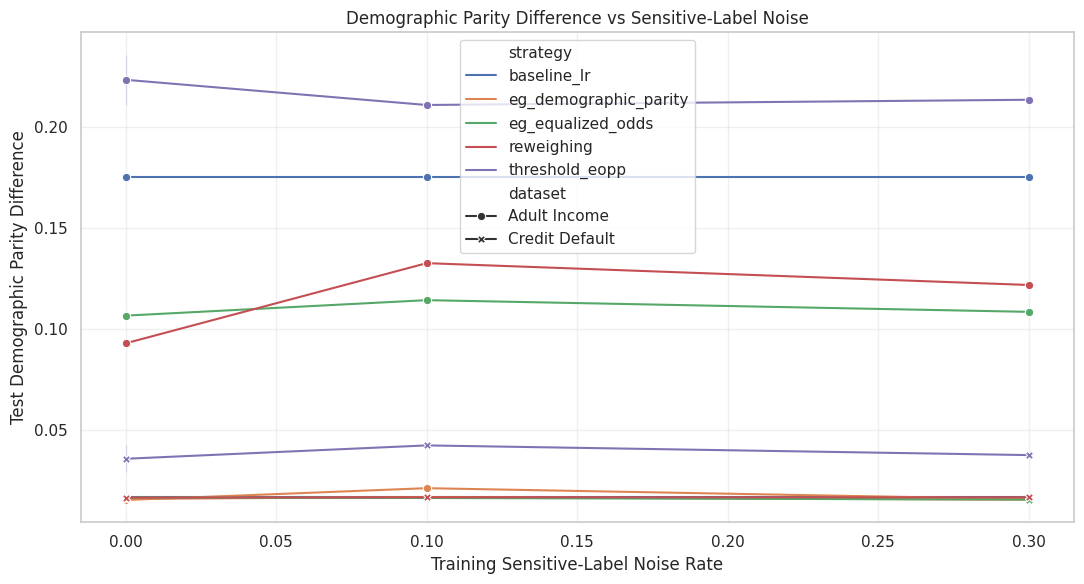

Saved: project22_outputs/figures/rq1_dp_vs_noise.png


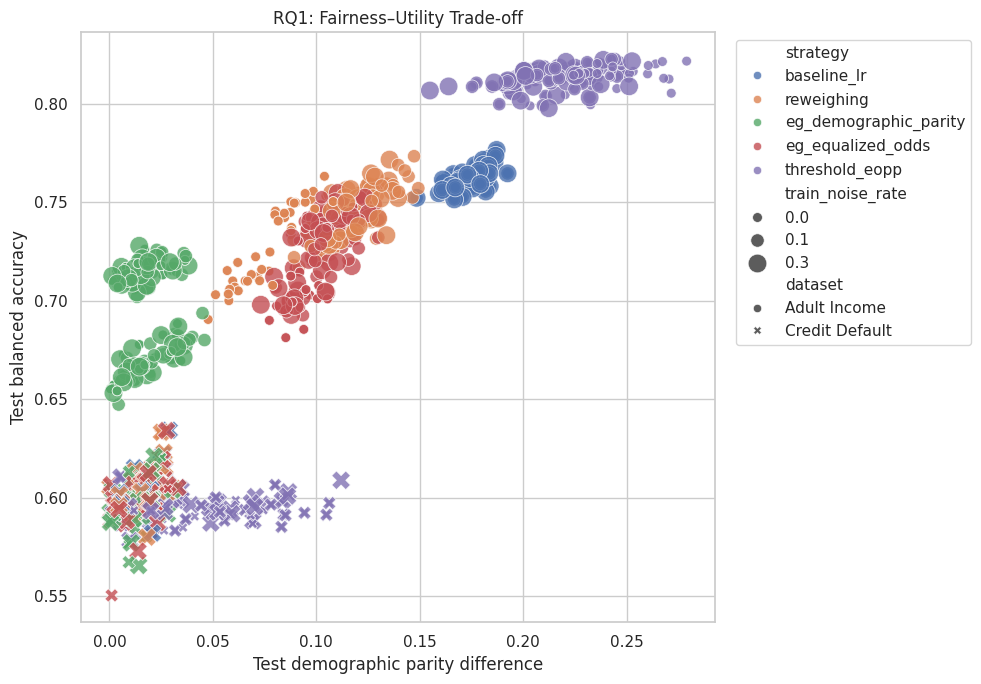

Saved: project22_outputs/figures/RQ1_Figure2_Fairness_Utility.png


In [17]:

# ============================================================
# RQ1 — SAVE FAIRNESS VS NOISE FIGURE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if not rq1_summary.empty:

    plot_data = rq1_summary[
        rq1_summary["group_design"] == "natural"
    ].copy()

    plt.figure(figsize=(11, 6))

    sns.lineplot(
        data=plot_data,
        x="train_noise_rate",
        y="mean_test_dp_diff",
        hue="strategy",
        style="dataset",
        markers=True,
        dashes=False
    )

    plt.title(
        "Demographic Parity Difference vs Sensitive-Label Noise"
    )
    plt.xlabel("Training Sensitive-Label Noise Rate")
    plt.ylabel("Test Demographic Parity Difference")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    figure_path = FIG_DIR / "rq1_dp_vs_noise.png"

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", figure_path)

else:
    print("RQ1 summary is empty. Cannot generate figure.")


# ============================================================
# RQ1 — FIGURE 2: FAIRNESS-UTILITY TRADE-OFF
# ============================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=results,
    x="test_dp_diff",
    y="test_balanced_accuracy",
    hue="strategy",
    style="dataset",
    size="train_noise_rate",
    sizes=(50, 180),
    alpha=0.8
)

plt.xlabel("Test demographic parity difference")
plt.ylabel("Test balanced accuracy")
plt.title("RQ1: Fairness–Utility Trade-off")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

save_figure("RQ1_Figure2_Fairness_Utility.png")



## 12. RQ2 — False reassurance, selector disagreement and regret

False reassurance is defined as a candidate that passes the fairness threshold on corrupted validation group labels but fails on clean validation group labels. The selector comparison reports disagreement with the clean-label oracle and clean-test fairness regret. Threshold sensitivity is evaluated at 0.03, 0.05 and 0.08.

In [23]:

# ============================================================
# PROJECT 22 — SELECTOR RESULTS COMPARISON
# ============================================================

if not selections.empty:

    # Use the actual column names from Section 10
    selkey = [
        "dataset",
        "seed",
        "group_design",
        "train_noise_rate",
        "validation_noise_rate",
        "noise_mode",
        "fairness_threshold",
        "utility_loss_floor",
        "ablation"
    ]

    # Verify required columns
    required = selkey + [
        "selector",
        "selected_strategy",
        "test_dp_diff",
        "test_balanced_accuracy"
    ]

    missing = [
        col for col in required
        if col not in selections.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns in selector results: {missing}"
        )

    # Pivot selector results
    wide = selections.pivot_table(
        index=selkey,
        columns="selector",
        values=[
            "selected_strategy",
            "test_dp_diff",
            "test_balanced_accuracy"
        ],
        aggfunc="first"
    )

    # Flatten multi-level column names
    wide.columns = [
        "_".join(map(str, col))
        for col in wide.columns
    ]

    wide = wide.reset_index()

    print("Selector comparison table:")
    print("Rows:", len(wide))

    display(wide.head(10))

else:
    print("No selector results available yet.")


Selector comparison table:
Rows: 1280


,dataset,seed,group_design,train_noise_rate,validation_noise_rate,noise_mode,fairness_threshold,utility_loss_floor,ablation,selected_strategy_naive,selected_strategy_oracle,selected_strategy_safeguard,test_balanced_accuracy_naive,test_balanced_accuracy_oracle,test_balanced_accuracy_safeguard,test_dp_diff_naive,test_dp_diff_oracle,test_dp_diff_safeguard
0,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.660087,0.660087,0.761571,0.005885,0.005885,0.161170
1,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
2,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_utility_floor,NaN,NaN,eg_demographic_parity,NaN,NaN,0.660087,NaN,NaN,0.005885
3,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_worst_case,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
4,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.660087,0.660087,0.761571,0.005885,0.005885,0.161170
5,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
6,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_utility_floor,NaN,NaN,eg_demographic_parity,NaN,NaN,0.660087,NaN,NaN,0.005885
7,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_worst_case,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
8,Adult Income,17,70_30,0.1,0.0,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.659159,0.659159,0.761571,0.004822,0.004822,0.161170
9,Adult Income,17,70_30,0.1,0.0,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170


RQ2 selector comparison coverage
Selector comparison rows: 320
Naive performance available: 320
Oracle performance available: 320

Missing naive performance:
Empty DataFrame
Columns: [dataset, seed, group_design, train_noise_rate, validation_noise_rate, noise_mode, naive_selected]
Index: []

RQ2 FIGURE 2 SUMMARY


,dataset,train_noise_rate,validation_noise_rate,noise_mode,disagreement_rate,mean_naive_regret,mean_oracle_regret,n_seeds
0,Adult Income,0.0,0.0,symmetric,0.000,0.120960,0.120960,20
1,Adult Income,0.0,0.1,symmetric,0.000,0.121951,0.121951,20
2,Adult Income,0.1,0.0,symmetric,0.000,0.118212,0.118212,20
3,Adult Income,0.3,0.3,minority_to_majority,0.000,0.120879,0.120879,20
4,Credit Default,0.0,0.0,symmetric,0.000,0.005945,0.005945,20
5,Credit Default,0.0,0.1,symmetric,0.550,0.006585,0.009193,20
6,Credit Default,0.1,0.0,symmetric,0.000,0.007609,0.007609,20
7,Credit Default,0.3,0.3,minority_to_majority,0.625,0.007922,0.009215,20


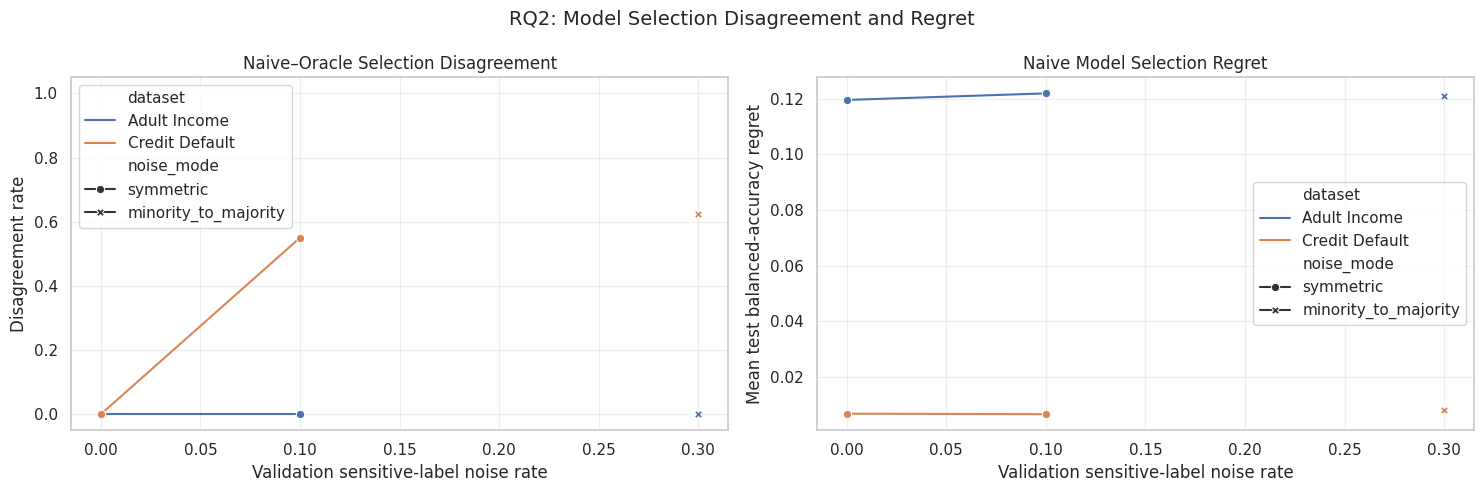

Saved: project22_outputs/figures/RQ2_Figure2_Selection_Regret.png


In [25]:

# ============================================================
# RQ2 — FIGURE 2
# SELECTION DISAGREEMENT AND MODEL SELECTION REGRET
# ============================================================

condition_cols = [
    "dataset",
    "seed",
    "group_design",
    "train_noise_rate",
    "validation_noise_rate",
    "noise_mode"
]

# ------------------------------------------------------------
# 1. PREPARE FULL-ABLATION SELECTOR RESULTS
# ------------------------------------------------------------

full = selections[
    selections["ablation"].eq("full")
].copy()

comparison = full[
    full["selector"].isin(["naive", "oracle"])
].copy()

# Pivot selected strategies
selected_wide = comparison.pivot_table(
    index=condition_cols,
    columns="selector",
    values="selected_strategy",
    aggfunc="first"
).reset_index()

selected_wide.columns.name = None

if not {"naive", "oracle"}.issubset(selected_wide.columns):
    raise ValueError(
        "Both naive and oracle selector results are required."
    )

selected_wide = selected_wide.rename(
    columns={
        "naive": "naive_selected",
        "oracle": "oracle_selected"
    }
)

# Calculate disagreement
selected_wide["naive_oracle_disagreement"] = (
    selected_wide["naive_selected"]
    != selected_wide["oracle_selected"]
).astype(float)


# ------------------------------------------------------------
# 2. PREPARE MODEL TEST PERFORMANCE
# ------------------------------------------------------------

required_model_cols = condition_cols + [
    "strategy",
    "test_balanced_accuracy"
]

missing = [
    c for c in required_model_cols
    if c not in results.columns
]

if missing:
    raise ValueError(
        f"Missing model-result columns: {missing}"
    )

model_metrics = results[required_model_cols].copy()

# Ensure numeric values
model_metrics["test_balanced_accuracy"] = pd.to_numeric(
    model_metrics["test_balanced_accuracy"],
    errors="coerce"
)

# One record per condition and strategy
model_metrics = model_metrics.drop_duplicates(
    subset=condition_cols + ["strategy"],
    keep="last"
)


# ------------------------------------------------------------
# 3. ATTACH NAIVE AND ORACLE PERFORMANCE
# ------------------------------------------------------------

naive_metrics = model_metrics.rename(
    columns={
        "strategy": "naive_selected",
        "test_balanced_accuracy": "naive_test_balanced_accuracy"
    }
)

oracle_metrics = model_metrics.rename(
    columns={
        "strategy": "oracle_selected",
        "test_balanced_accuracy": "oracle_test_balanced_accuracy"
    }
)

regret_data = selected_wide.merge(
    naive_metrics,
    on=condition_cols + ["naive_selected"],
    how="left",
    validate="one_to_one"
)

regret_data = regret_data.merge(
    oracle_metrics,
    on=condition_cols + ["oracle_selected"],
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 4. CALCULATE TEST-SET REGRET
# ------------------------------------------------------------

# Best observed test balanced accuracy among available strategies.
# This is descriptive test-set regret, not an unbiased
# validation-time model-selection estimate.

best_test = (
    model_metrics
    .groupby(condition_cols)["test_balanced_accuracy"]
    .max()
    .rename("best_test_balanced_accuracy")
    .reset_index()
)

regret_data = regret_data.merge(
    best_test,
    on=condition_cols,
    how="left",
    validate="one_to_one"
)

regret_data["naive_regret"] = (
    regret_data["best_test_balanced_accuracy"]
    - regret_data["naive_test_balanced_accuracy"]
)

regret_data["oracle_regret"] = (
    regret_data["best_test_balanced_accuracy"]
    - regret_data["oracle_test_balanced_accuracy"]
)


# ------------------------------------------------------------
# 5. CHECK DATA COVERAGE
# ------------------------------------------------------------

print("RQ2 selector comparison coverage")
print("Selector comparison rows:", len(selected_wide))
print(
    "Naive performance available:",
    regret_data["naive_test_balanced_accuracy"].notna().sum()
)
print(
    "Oracle performance available:",
    regret_data["oracle_test_balanced_accuracy"].notna().sum()
)

print("\nMissing naive performance:")
print(
    regret_data[
        regret_data["naive_test_balanced_accuracy"].isna()
    ][condition_cols + ["naive_selected"]].head()
)


# ------------------------------------------------------------
# 6. AGGREGATE RESULTS
# ------------------------------------------------------------

summary = (
    regret_data
    .groupby(
        [
            "dataset",
            "train_noise_rate",
            "validation_noise_rate",
            "noise_mode"
        ],
        as_index=False
    )
    .agg(
        disagreement_rate=(
            "naive_oracle_disagreement", "mean"
        ),
        mean_naive_regret=("naive_regret", "mean"),
        mean_oracle_regret=("oracle_regret", "mean"),
        n_seeds=("seed", "nunique")
    )
)

print("\nRQ2 FIGURE 2 SUMMARY")
display(summary.head(20))


# ------------------------------------------------------------
# 7. GENERATE FIGURE 2
# ------------------------------------------------------------

if not summary.empty:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 5)
    )

    sns.lineplot(
        data=summary,
        x="validation_noise_rate",
        y="disagreement_rate",
        hue="dataset",
        style="noise_mode",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=axes[0]
    )

    axes[0].set_title(
        "Naive–Oracle Selection Disagreement"
    )
    axes[0].set_xlabel(
        "Validation sensitive-label noise rate"
    )
    axes[0].set_ylabel("Disagreement rate")
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].grid(True, alpha=0.3)

    sns.lineplot(
        data=summary,
        x="validation_noise_rate",
        y="mean_naive_regret",
        hue="dataset",
        style="noise_mode",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=axes[1]
    )

    axes[1].set_title("Naive Model Selection Regret")
    axes[1].set_xlabel(
        "Validation sensitive-label noise rate"
    )
    axes[1].set_ylabel(
        "Mean test balanced-accuracy regret"
    )
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(
        "RQ2: Model Selection Disagreement and Regret",
        fontsize=14
    )

    plt.tight_layout()

    path2 = FIG_DIR / "RQ2_Figure2_Selection_Regret.png"

    fig.savefig(
        path2,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", path2)

else:
    print("No valid RQ2 selector results available.")


In [26]:
print("WIDE DATAFRAME")
print("Shape:", wide.shape)
print("Columns:", wide.columns.tolist())
display(wide.head(10))

print("\nRQ2 SELECTOR DISAGREEMENT DATA")
print("Shape:", rq2_disagreement.shape if "rq2_disagreement" in globals() else "Not found")

print("\nRQ2 SUMMARY")
print(rq2_summary.columns.tolist())

WIDE DATAFRAME
Shape: (1280, 18)
Columns: ['dataset', 'seed', 'group_design', 'train_noise_rate', 'validation_noise_rate', 'noise_mode', 'fairness_threshold', 'utility_loss_floor', 'ablation', 'selected_strategy_naive', 'selected_strategy_oracle', 'selected_strategy_safeguard', 'test_balanced_accuracy_naive', 'test_balanced_accuracy_oracle', 'test_balanced_accuracy_safeguard', 'test_dp_diff_naive', 'test_dp_diff_oracle', 'test_dp_diff_safeguard']


,dataset,seed,group_design,train_noise_rate,validation_noise_rate,noise_mode,fairness_threshold,utility_loss_floor,ablation,selected_strategy_naive,selected_strategy_oracle,selected_strategy_safeguard,test_balanced_accuracy_naive,test_balanced_accuracy_oracle,test_balanced_accuracy_safeguard,test_dp_diff_naive,test_dp_diff_oracle,test_dp_diff_safeguard
0,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.660087,0.660087,0.761571,0.005885,0.005885,0.161170
1,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
2,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_utility_floor,NaN,NaN,eg_demographic_parity,NaN,NaN,0.660087,NaN,NaN,0.005885
3,Adult Income,17,70_30,0.0,0.0,symmetric,0.05,0.015,no_worst_case,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
4,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.660087,0.660087,0.761571,0.005885,0.005885,0.161170
5,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
6,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_utility_floor,NaN,NaN,eg_demographic_parity,NaN,NaN,0.660087,NaN,NaN,0.005885
7,Adult Income,17,70_30,0.0,0.1,symmetric,0.05,0.015,no_worst_case,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170
8,Adult Income,17,70_30,0.1,0.0,symmetric,0.05,0.015,full,eg_demographic_parity,eg_demographic_parity,baseline_lr,0.659159,0.659159,0.761571,0.004822,0.004822,0.161170
9,Adult Income,17,70_30,0.1,0.0,symmetric,0.05,0.015,no_correction,NaN,NaN,baseline_lr,NaN,NaN,0.761571,NaN,NaN,0.161170



RQ2 SELECTOR DISAGREEMENT DATA
Shape: Not found

RQ2 SUMMARY
['dataset', 'validation_noise_rate', 'noise_mode', 'strategy', 'false_reassurance_rate', 'apparent_dp', 'clean_validation_dp', 'n', 'fairness_threshold']


In [29]:

import numpy as np
from scipy import stats

def mean_ci(values, confidence=0.95):
    """
    Calculate mean and two-sided Student-t confidence interval.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)

    if n == 0:
        return np.nan, np.nan, np.nan

    mean = np.mean(values)

    if n == 1:
        return mean, np.nan, np.nan

    sem = stats.sem(values)
    margin = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    ) * sem

    return mean, mean - margin, mean + margin

print("mean_ci() defined successfully.")


mean_ci() defined successfully.


## 13. RQ3 — Safeguard, utility floor, ablations and misspecification

Compare safeguard against naïve and oracle selection at the same dataset, seed, group design, corruption condition, fairness threshold and utility floor. Report worst-case test disparity over noise conditions, balanced-accuracy loss, feasibility, and paired bootstrap confidence intervals. Ablations isolate correction, worst-case uncertainty and utility-floor components. The `0.5x`, `1.0x`, and `1.5x` corruption-rate multipliers provide the proposal's ±50% misspecification sensitivity.

In [30]:

# ============================================================
# RQ3 — SAFEGUARD PERFORMANCE AND PAIRED COMPARISON
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. RQ3 SUMMARY
# ------------------------------------------------------------

if not selections.empty:

    rq3_summary = (
        selections
        .groupby(
            [
                "dataset",
                "group_design",
                "train_noise_rate",
                "validation_noise_rate",
                "noise_mode",
                "fairness_threshold",
                "utility_loss_floor",
                "ablation",
                "selector"
            ],
            as_index=False
        )
        .agg(
            mean_test_dp=("test_dp_diff", "mean"),
            mean_test_eopp=("test_eopp_diff", "mean"),
            mean_test_eo=("test_eo_diff", "mean"),
            mean_test_ba=("test_balanced_accuracy", "mean"),
            n=("test_dp_diff", "count"),
            n_seeds=("seed", "nunique")
        )
    )

else:
    rq3_summary = pd.DataFrame()

print("RQ3 SUMMARY")
display(rq3_summary.head(15))


# ------------------------------------------------------------
# 2. PAIRED SEED-LEVEL COMPARISON
# SAFEGUARD MINUS NAIVE
# ------------------------------------------------------------

if not selections.empty:

    pair_cols = [
        "dataset",
        "seed",
        "group_design",
        "train_noise_rate",
        "validation_noise_rate",
        "noise_mode",
        "fairness_threshold",
        "utility_loss_floor",
        "ablation"
    ]

    # Use full ablation for the primary comparison
    paired_data = selections[
        selections["ablation"].eq("full")
        & selections["selector"].isin(["naive", "safeguard"])
    ].copy()

    # Paired DP comparison
    dpwide = (
        paired_data
        .pivot_table(
            index=pair_cols,
            columns="selector",
            values="test_dp_diff",
            aggfunc="first"
        )
    )

    paired = []

    if {"naive", "safeguard"}.issubset(dpwide.columns):

        dpwide = dpwide.dropna(
            subset=["naive", "safeguard"]
        )

        for ds, group in dpwide.groupby(level="dataset"):

            diff = (
                group["safeguard"]
                - group["naive"]
            ).to_numpy()

            if len(diff) > 0:
                mean_diff, ci_low, ci_high = mean_ci(diff)

                paired.append({
                    "dataset": ds,
                    "outcome": "safeguard_minus_naive_test_dp",
                    "mean_difference": mean_diff,
                    "ci95_low": ci_low,
                    "ci95_high": ci_high,
                    "n_pairs": len(diff)
                })

    # Paired balanced-accuracy comparison
    bawide = (
        paired_data
        .pivot_table(
            index=pair_cols,
            columns="selector",
            values="test_balanced_accuracy",
            aggfunc="first"
        )
    )

    if {"naive", "safeguard"}.issubset(bawide.columns):

        bawide = bawide.dropna(
            subset=["naive", "safeguard"]
        )

        for ds, group in bawide.groupby(level="dataset"):

            diff = (
                group["safeguard"]
                - group["naive"]
            ).to_numpy()

            if len(diff) > 0:
                mean_diff, ci_low, ci_high = mean_ci(diff)

                paired.append({
                    "dataset": ds,
                    "outcome": "safeguard_minus_naive_test_balanced_accuracy",
                    "mean_difference": mean_diff,
                    "ci95_low": ci_low,
                    "ci95_high": ci_high,
                    "n_pairs": len(diff)
                })

    rq3_paired = pd.DataFrame(paired)

else:
    rq3_paired = pd.DataFrame()

print("\nRQ3 PAIRED COMPARISON")
display(rq3_paired)


# ------------------------------------------------------------
# 3. SAVE RQ3 TABLES
# ------------------------------------------------------------

if not rq3_summary.empty:
    rq3_summary.to_csv(
        FIG_DIR / "RQ3_Summary.csv",
        index=False
    )

if not rq3_paired.empty:
    rq3_paired.to_csv(
        FIG_DIR / "RQ3_Paired_Comparison.csv",
        index=False
    )

print("\nRQ3 tables saved successfully.")


RQ3 SUMMARY


,dataset,group_design,train_noise_rate,validation_noise_rate,noise_mode,fairness_threshold,utility_loss_floor,ablation,selector,mean_test_dp,mean_test_eopp,mean_test_eo,mean_test_ba,n,n_seeds
0,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,full,naive,0.018365,0.255316,0.255316,0.668634,20,20
1,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,full,oracle,0.018365,0.255316,0.255316,0.668634,20,20
2,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,full,safeguard,0.172494,0.094536,0.099501,0.760651,20,20
3,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,no_correction,safeguard,0.172494,0.094536,0.099501,0.760651,20,20
4,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,no_utility_floor,safeguard,0.018365,0.255316,0.255316,0.668634,20,20
5,Adult Income,70_30,0.0,0.0,symmetric,0.05,0.015,no_worst_case,safeguard,0.172494,0.094536,0.099501,0.760651,20,20
6,Adult Income,70_30,0.0,0.1,symmetric,0.05,0.015,full,naive,0.018365,0.255316,0.255316,0.668634,20,20
7,Adult Income,70_30,0.0,0.1,symmetric,0.05,0.015,full,oracle,0.018365,0.255316,0.255316,0.668634,20,20
8,Adult Income,70_30,0.0,0.1,symmetric,0.05,0.015,full,safeguard,0.172494,0.094536,0.099501,0.760651,20,20
9,Adult Income,70_30,0.0,0.1,symmetric,0.05,0.015,no_correction,safeguard,0.172494,0.094536,0.099501,0.760651,20,20



RQ3 PAIRED COMPARISON


,dataset,outcome,mean_difference,ci95_low,ci95_high,n_pairs
0,Adult Income,safeguard_minus_naive_test_dp,0.133631,0.129082,0.138181,160
1,Credit Default,safeguard_minus_naive_test_dp,0.000732,-0.000056,0.001520,160
2,Adult Income,safeguard_minus_naive_test_balanced_accuracy,0.065761,0.061669,0.069853,160
3,Credit Default,safeguard_minus_naive_test_balanced_accuracy,0.002601,0.001078,0.004124,160



RQ3 tables saved successfully.


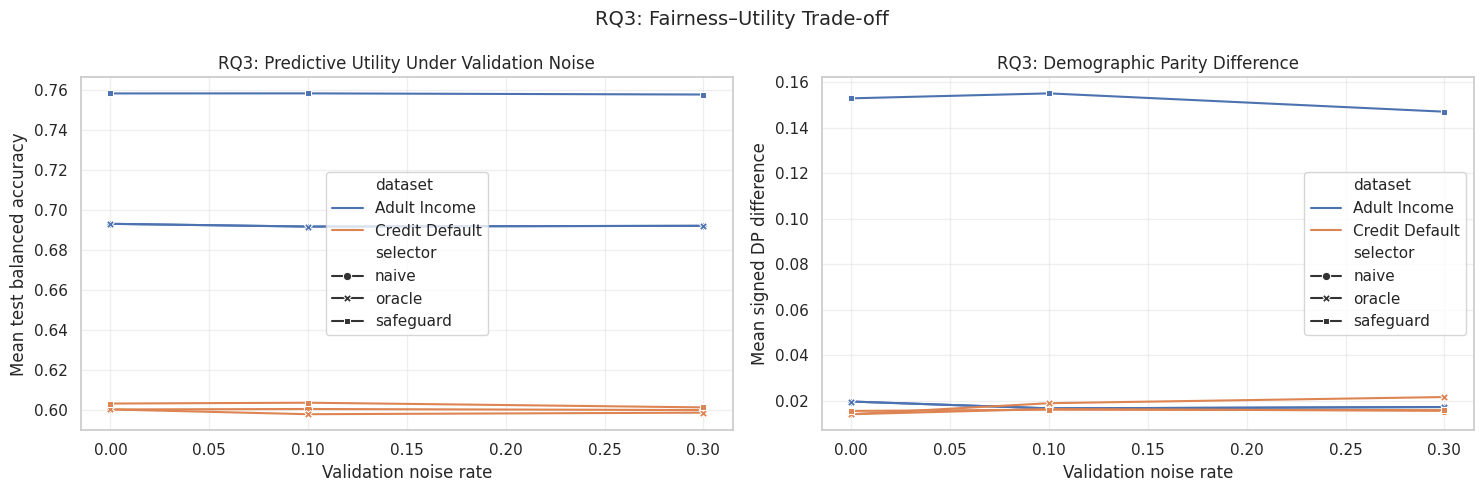

Saved: project22_outputs/figures/RQ3_Figure1_Fairness_Utility.png


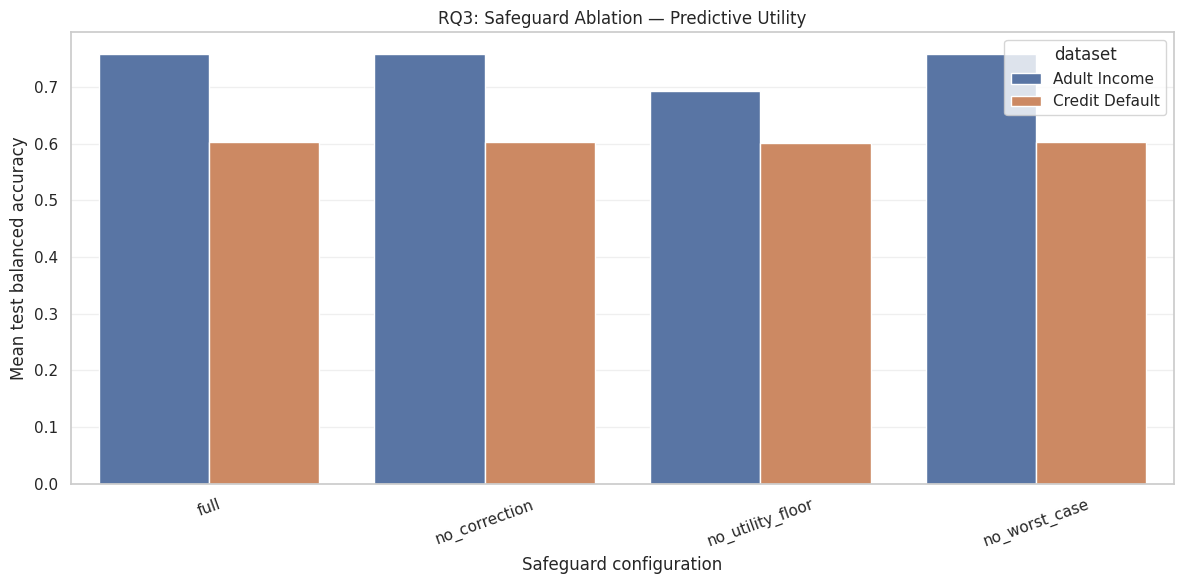

Saved: project22_outputs/figures/RQ3_Figure2_Safeguard_Ablation.png

RQ3 FIGURE INVENTORY
RQ3_Figure1_Fairness_Utility.png SAVED
RQ3_Figure2_Safeguard_Ablation.png SAVED


In [32]:

# ============================================================
# RQ3 — FAIRNESS–UTILITY TRADE-OFF PLOTS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

FIG_DIR.mkdir(parents=True, exist_ok=True)

if rq3_summary.empty:
    print("RQ3 summary is empty. Nothing to plot.")

else:

    plot_data = rq3_summary.copy()

    # --------------------------------------------------------
    # VALIDATE COLUMNS
    # --------------------------------------------------------

    required_cols = [
        "dataset",
        "group_design",
        "train_noise_rate",
        "validation_noise_rate",
        "noise_mode",
        "ablation",
        "selector",
        "mean_test_dp",
        "mean_test_eopp",
        "mean_test_eo",
        "mean_test_ba"
    ]

    missing = [
        col for col in required_cols
        if col not in plot_data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing RQ3 columns: {missing}"
        )

    # --------------------------------------------------------
    # PRIMARY ANALYSIS: FULL ABLATION
    # --------------------------------------------------------

    primary = plot_data[
        plot_data["ablation"].eq("full")
    ].copy()

    # --------------------------------------------------------
    # FIGURE 1: BALANCED ACCURACY
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 5)
    )

    sns.lineplot(
        data=primary,
        x="validation_noise_rate",
        y="mean_test_ba",
        hue="dataset",
        style="selector",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=axes[0]
    )

    axes[0].set_title(
        "RQ3: Predictive Utility Under Validation Noise"
    )
    axes[0].set_xlabel("Validation noise rate")
    axes[0].set_ylabel("Mean test balanced accuracy")
    axes[0].grid(True, alpha=0.3)

    # --------------------------------------------------------
    # FIGURE 2: DEMOGRAPHIC PARITY
    # --------------------------------------------------------

    sns.lineplot(
        data=primary,
        x="validation_noise_rate",
        y="mean_test_dp",
        hue="dataset",
        style="selector",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=axes[1]
    )

    axes[1].set_title(
        "RQ3: Demographic Parity Difference"
    )
    axes[1].set_xlabel("Validation noise rate")
    axes[1].set_ylabel("Mean signed DP difference")
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(
        "RQ3: Fairness–Utility Trade-off",
        fontsize=14
    )

    plt.tight_layout()

    path = FIG_DIR / "RQ3_Figure1_Fairness_Utility.png"

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", path)

    # --------------------------------------------------------
    # FIGURE 3: ABLATION COMPARISON
    # --------------------------------------------------------

    ablation_data = plot_data[
        plot_data["selector"].eq("safeguard")
    ].copy()

    if not ablation_data.empty:

        fig, ax = plt.subplots(figsize=(12, 6))

        sns.barplot(
            data=ablation_data,
            x="ablation",
            y="mean_test_ba",
            hue="dataset",
            errorbar=None,
            ax=ax
        )

        ax.set_title(
            "RQ3: Safeguard Ablation — Predictive Utility"
        )
        ax.set_xlabel("Safeguard configuration")
        ax.set_ylabel("Mean test balanced accuracy")
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()

        path = FIG_DIR / "RQ3_Figure2_Safeguard_Ablation.png"

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

        print("Saved:", path)

print("\nRQ3 FIGURE INVENTORY")

for filename in [
    "RQ3_Figure1_Fairness_Utility.png",
    "RQ3_Figure2_Safeguard_Ablation.png"
]:
    path = FIG_DIR / filename
    print(
        filename,
        "SAVED" if path.exists() else "NOT GENERATED"
    )


## 14. RQ4 — Group prevalence, corruption direction and target-class imbalance

The group design varies the training group composition. The target-class prevalence factor is also tested through controlled training resampling to approximate 10%, 25% and 40% positive-class rates, while preserving the untouched validation/test sets. This isolates training-distribution effects; results must be described as simulated resampling conditions, not naturally occurring prevalence changes.

The primary factorial loop above already covers group prevalence. The following helper creates target-prevalence variants for a focused extension on each dataset/seed and records fairness/utility under clean test labels.

In [33]:
def resample_target_prevalence(X,y,a,target_rate,seed):
    rng=np.random.default_rng(seed); y=np.asarray(y); a=np.asarray(a)
    pos=np.where(y==1)[0]; neg=np.where(y==0)[0]
    n=min(len(pos),len(neg))
    npos=max(1,int(round(n*target_rate/(1-target_rate))))
    nneg=min(len(neg),int(round(npos*(1-target_rate)/target_rate)))
    npos=min(len(pos),int(round(nneg*target_rate/(1-target_rate))))
    ids=np.concatenate([rng.choice(pos,npos,replace=False),rng.choice(neg,nneg,replace=False)])
    rng.shuffle(ids)
    return X.iloc[ids].reset_index(drop=True),y[ids],a[ids]

# Run focused target-class imbalance sensitivity for baseline and reweighing.
target_imbalance_rows=[]
for ds,(X_all,y_all,a_all) in DATASETS.items():
    for seed in SEEDS:
        sp=split_data(X_all,y_all,a_all,seed+500)
        for prevalence in [.10,.25,.40]:
            Xr,yr,ar=resample_target_prevalence(sp["Xtr"],sp["ytr"],sp["atr"],prevalence,seed+int(prevalence*1000))
            pre=make_preprocessor(Xr); Xrt=pre.fit_transform(Xr); Xvt=pre.transform(sp["Xva"]); Xtt=pre.transform(sp["Xte"])
            for strategy in ["baseline_lr","reweighing"]:
                try:
                    fitted=fit_strategy(strategy,Xrt,yr,ar,seed)
                    pred=predict_strategy(fitted,strategy,Xtt)
                    target_imbalance_rows.append({"dataset":ds,"seed":seed,"training_target_rate":prevalence,
                        "strategy":strategy,**evaluate(sp["yte"],pred,sp["ate"])})
                except Exception as e:
                    failure_rows.append({"dataset":ds,"seed":seed,"strategy":strategy,"error":repr(e),"extension":"target_imbalance"})
target_imbalance=pd.DataFrame(target_imbalance_rows)
display(target_imbalance.groupby(["dataset","training_target_rate","strategy"],as_index=False).mean(numeric_only=True))

,dataset,training_target_rate,strategy,seed,accuracy,balanced_accuracy,selection_rate_g0,tpr_g0,fpr_g0,selection_rate_g1,tpr_g1,fpr_g1,dp_diff,eopp_diff,eo_diff
0,Adult Income,0.10,baseline_lr,695.0,0.829918,0.660349,0.036881,0.278227,0.006649,0.119714,0.347316,0.021910,0.082833,0.069089,0.069089
1,Adult Income,0.10,reweighing,695.0,0.825511,0.650506,0.065911,0.448347,0.017995,0.097608,0.292301,0.013936,0.031697,0.156046,0.156046
2,Adult Income,0.25,baseline_lr,695.0,0.851586,0.770073,0.082317,0.519140,0.027632,0.262394,0.631940,0.103637,0.180076,0.112800,0.112800
3,Adult Income,0.25,reweighing,695.0,0.847919,0.756001,0.126111,0.664512,0.058694,0.222149,0.565220,0.074765,0.096038,0.099292,0.099292
4,Adult Income,0.40,baseline_lr,695.0,0.833754,0.810571,0.120925,0.644593,0.055371,0.377897,0.788498,0.201465,0.256972,0.143905,0.150995
5,Adult Income,0.40,reweighing,695.0,0.836412,0.800651,0.168298,0.759117,0.094343,0.326448,0.727507,0.154137,0.158150,0.031610,0.059794
6,Credit Default,0.10,baseline_lr,695.0,0.785833,0.521311,0.009712,0.035718,0.002909,0.019846,0.061343,0.006577,0.010134,0.025625,0.025625
7,Credit Default,0.10,reweighing,695.0,0.785667,0.520934,0.009342,0.034371,0.002794,0.019990,0.061343,0.006765,0.010648,0.026972,0.026972
8,Credit Default,0.25,baseline_lr,695.0,0.818944,0.643470,0.096308,0.330466,0.035018,0.119017,0.327028,0.052656,0.022710,0.011542,0.017638
9,Credit Default,0.25,reweighing,695.0,0.818944,0.643200,0.096213,0.329999,0.035014,0.118329,0.325938,0.052112,0.022116,0.012025,0.017469


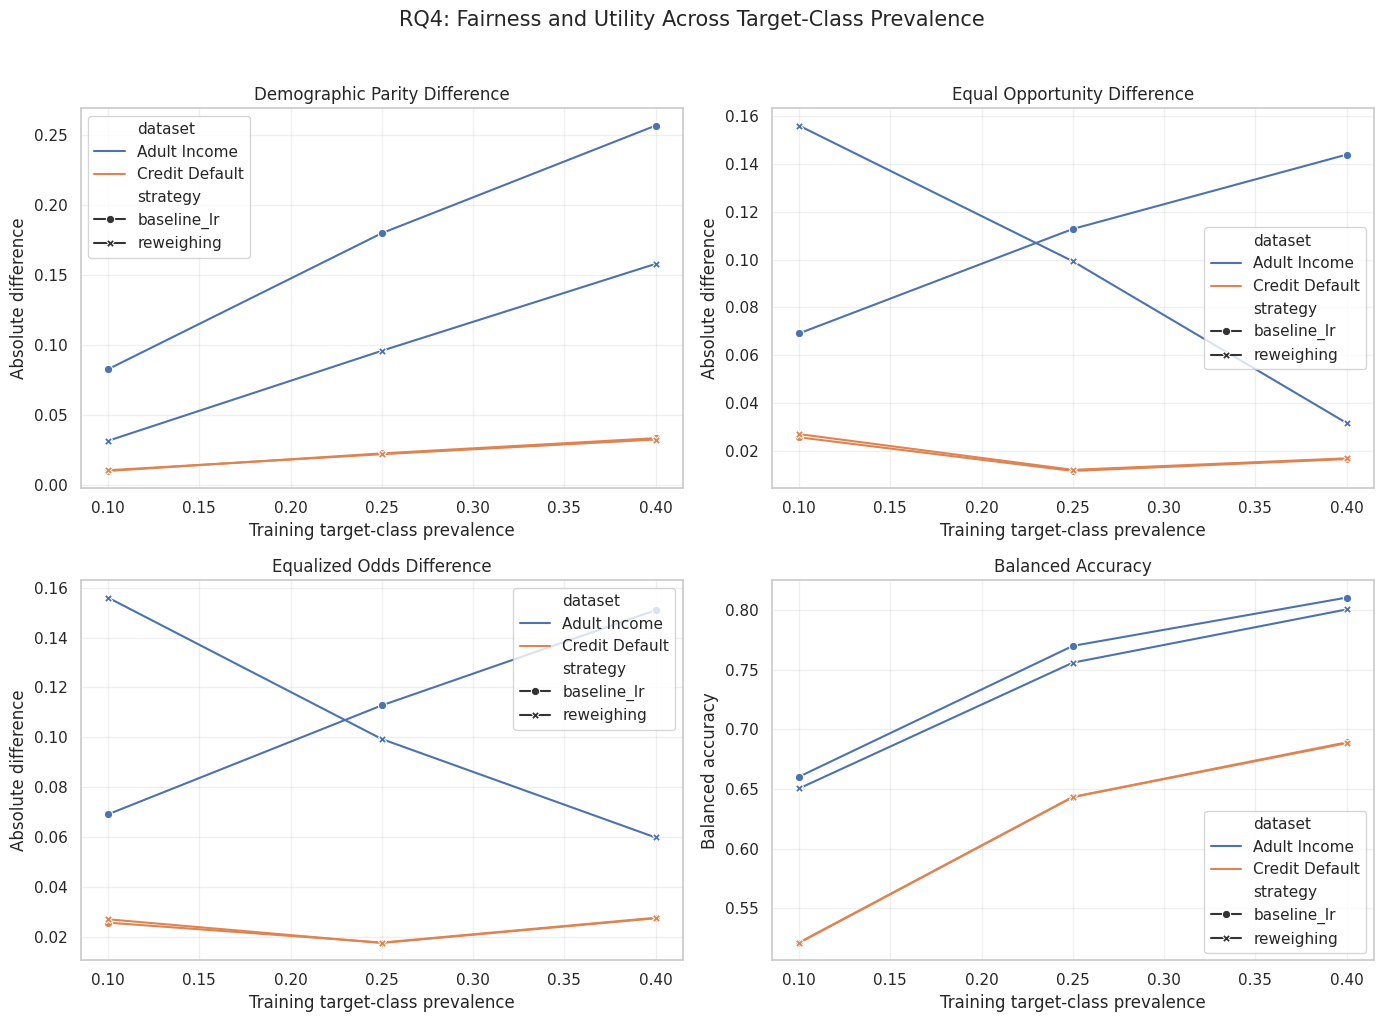

Saved: project22_outputs/figures/RQ4_Figure1_Target_Class_Prevalence.png


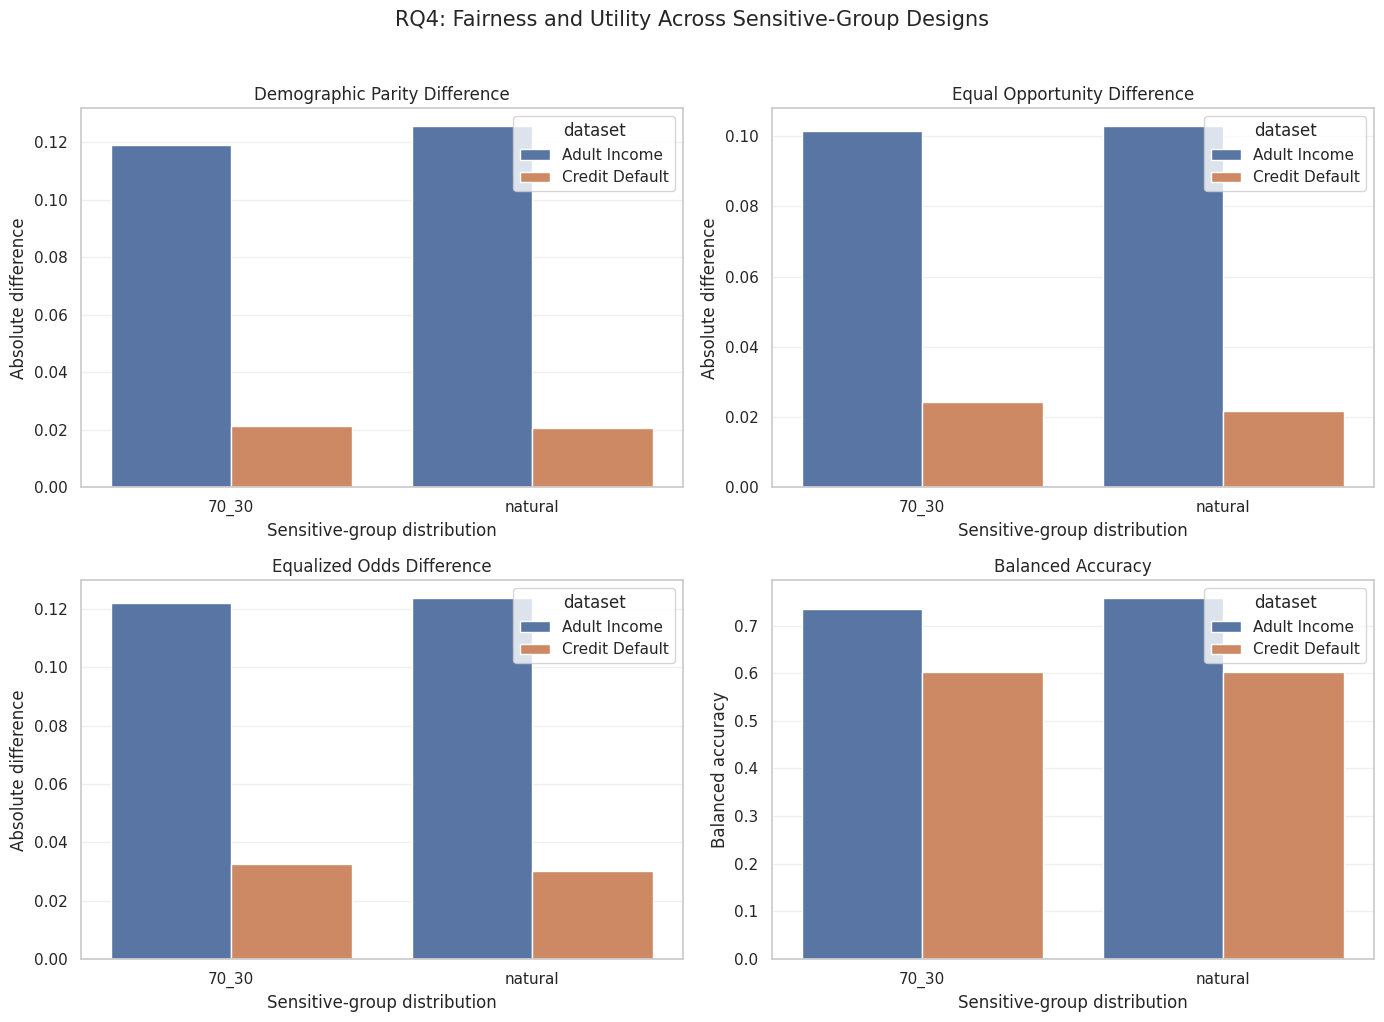

Saved: project22_outputs/figures/RQ4_Figure2_Group_Prevalence.png

RQ4 FIGURE INVENTORY
RQ4_Figure1_Target_Class_Prevalence.png: SAVED
RQ4_Figure2_Group_Prevalence.png: SAVED


In [34]:

# ============================================================
# RQ4 — FIGURE 1 & FIGURE 2
# TARGET-CLASS IMBALANCE AND GROUP PREVALENCE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

# ============================================================
# FIGURE 1 — TARGET-CLASS PREVALENCE
# ============================================================

if "target_imbalance" not in globals() or target_imbalance.empty:
    raise ValueError("Target imbalance results are unavailable.")

target_data = target_imbalance.copy()

required = [
    "dataset", "training_target_rate", "strategy",
    "dp_diff", "eopp_diff", "eo_diff", "balanced_accuracy"
]

missing = [c for c in required if c not in target_data.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

target_summary = (
    target_data
    .groupby(
        ["dataset", "training_target_rate", "strategy"],
        as_index=False
    )
    .agg(
        dp=("dp_diff", "mean"),
        eopp=("eopp_diff", "mean"),
        eo=("eo_diff", "mean"),
        ba=("balanced_accuracy", "mean")
    )
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = [
    ("dp", "Demographic Parity Difference"),
    ("eopp", "Equal Opportunity Difference"),
    ("eo", "Equalized Odds Difference"),
    ("ba", "Balanced Accuracy")
]

for ax, (metric, title) in zip(axes.flat, metrics):

    sns.lineplot(
        data=target_summary,
        x="training_target_rate",
        y=metric,
        hue="dataset",
        style="strategy",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Training target-class prevalence")
    ax.set_ylabel(
        "Balanced accuracy" if metric == "ba"
        else "Absolute difference"
    )
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "RQ4: Fairness and Utility Across Target-Class Prevalence",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

path1 = FIG_DIR / "RQ4_Figure1_Target_Class_Prevalence.png"
fig.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", path1)


# ============================================================
# FIGURE 2 — SENSITIVE GROUP DESIGN
# ============================================================

required_group = [
    "dataset", "group_design", "strategy",
    "test_dp_diff", "test_eopp_diff",
    "test_eo_diff", "test_balanced_accuracy"
]

missing_group = [c for c in required_group if c not in results.columns]

if missing_group:
    print("\nFigure 2 cannot be generated.")
    print("Missing columns in results:", missing_group)

else:

    group_data = results.copy()

    group_summary = (
        group_data
        .groupby(
            ["dataset", "group_design", "strategy"],
            as_index=False
        )
        .agg(
            dp=("test_dp_diff", "mean"),
            eopp=("test_eopp_diff", "mean"),
            eo=("test_eo_diff", "mean"),
            ba=("test_balanced_accuracy", "mean")
        )
    )

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    metrics = [
        ("dp", "Demographic Parity Difference"),
        ("eopp", "Equal Opportunity Difference"),
        ("eo", "Equalized Odds Difference"),
        ("ba", "Balanced Accuracy")
    ]

    for ax, (metric, title) in zip(axes.flat, metrics):

        sns.barplot(
            data=group_summary,
            x="group_design",
            y=metric,
            hue="dataset",
            errorbar=None,
            ax=ax
        )

        ax.set_title(title)
        ax.set_xlabel("Sensitive-group distribution")
        ax.set_ylabel(
            "Balanced accuracy" if metric == "ba"
            else "Absolute difference"
        )
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        "RQ4: Fairness and Utility Across Sensitive-Group Designs",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()

    path2 = FIG_DIR / "RQ4_Figure2_Group_Prevalence.png"
    fig.savefig(path2, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", path2)


# ============================================================
# FINAL FIGURE INVENTORY
# ============================================================

print("\nRQ4 FIGURE INVENTORY")

for filename in [
    "RQ4_Figure1_Target_Class_Prevalence.png",
    "RQ4_Figure2_Group_Prevalence.png"
]:
    path = FIG_DIR / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'NOT GENERATED'}")


## 15. RQ5 — Cross-dataset replication and effect sizes

The two datasets have different prediction targets and feature spaces. This is cross-context replication, not train-on-one/test-on-the-other domain adaptation. Compare within-dataset changes from each dataset's own zero-noise baseline, then compare those changes and strategy rankings.

In [35]:
# ============================================================
# RQ5 — CROSS-DATASET COMPARISON
# ============================================================

if not results.empty:

    # 1. Compare datasets under natural group distribution
    cross_dataset = results[
        results["group_design"] == "natural"
    ].copy()

    # 2. Aggregate performance across seeds and conditions
    rq5_summary = (
        cross_dataset
        .groupby(
            [
                "dataset",
                "strategy",
                "train_noise_rate",
                "validation_noise_rate",
                "noise_mode"
            ],
            as_index=False
        )
        .agg(
            mean_balanced_accuracy=(
                "test_balanced_accuracy", "mean"
            ),
            mean_dp_diff=("test_dp_diff", "mean"),
            mean_eopp_diff=("test_eopp_diff", "mean"),
            mean_eo_diff=("test_eo_diff", "mean"),
            seed_count=("seed", "nunique")
        )
    )

    print("RQ5 — CROSS-DATASET PERFORMANCE")
    print("=" * 60)

    display(rq5_summary.head(20))

    # 3. Compare strategy rankings across datasets
    ranking_data = (
        cross_dataset
        .groupby(["dataset", "strategy"], as_index=False)
        .agg(
            balanced_accuracy=(
                "test_balanced_accuracy", "mean"
            ),
            dp_diff=("test_dp_diff", "mean"),
            eopp_diff=("test_eopp_diff", "mean"),
            eo_diff=("test_eo_diff", "mean")
        )
    )

    # Lower fairness differences are better
    ranking_data["dp_rank"] = (
        ranking_data.groupby("dataset")["dp_diff"]
        .rank(method="average", ascending=True)
    )

    ranking_data["utility_rank"] = (
        ranking_data.groupby("dataset")["balanced_accuracy"]
        .rank(method="average", ascending=False)
    )

    display(ranking_data)

    # 4. Spearman ranking agreement across datasets
    from scipy.stats import spearmanr

    print("\nSPEARMAN RANKING AGREEMENT")
    print("-" * 60)

    for metric in ["dp_rank", "utility_rank"]:

        pivot = ranking_data.pivot(
            index="strategy",
            columns="dataset",
            values=metric
        ).dropna()

        if pivot.shape[1] >= 2 and len(pivot) >= 2:

            rho, p_value = spearmanr(
                pivot.iloc[:, 0],
                pivot.iloc[:, 1]
            )

            print(
                f"{metric}: rho={rho:.3f}, "
                f"p-value={p_value:.4f}, "
                f"strategies compared={len(pivot)}"
            )

        else:
            print(
                f"{metric}: Insufficient comparable strategies."
            )

else:
    print("No experiment results available.")

RQ5 — CROSS-DATASET PERFORMANCE


,dataset,strategy,train_noise_rate,validation_noise_rate,noise_mode,mean_balanced_accuracy,mean_dp_diff,mean_eopp_diff,mean_eo_diff,seed_count
0,Adult Income,baseline_lr,0.0,0.0,symmetric,0.763727,0.175037,0.094121,0.099910,20
1,Adult Income,baseline_lr,0.0,0.1,symmetric,0.763727,0.175037,0.094121,0.099910,20
2,Adult Income,baseline_lr,0.1,0.0,symmetric,0.763727,0.175037,0.094121,0.099910,20
3,Adult Income,baseline_lr,0.3,0.3,minority_to_majority,0.763727,0.175037,0.094121,0.099910,20
4,Adult Income,eg_demographic_parity,0.0,0.0,symmetric,0.714708,0.015099,0.280277,0.280277,20
5,Adult Income,eg_demographic_parity,0.0,0.1,symmetric,0.714708,0.015099,0.280277,0.280277,20
6,Adult Income,eg_demographic_parity,0.1,0.0,symmetric,0.715984,0.020947,0.268271,0.268271,20
7,Adult Income,eg_demographic_parity,0.3,0.3,minority_to_majority,0.714744,0.015478,0.278274,0.278274,20
8,Adult Income,eg_equalized_odds,0.0,0.0,symmetric,0.737933,0.106439,0.031838,0.035424,20
9,Adult Income,eg_equalized_odds,0.0,0.1,symmetric,0.737933,0.106439,0.031838,0.035424,20


,dataset,strategy,balanced_accuracy,dp_diff,eopp_diff,eo_diff,dp_rank,utility_rank
0,Adult Income,baseline_lr,0.763727,0.175037,0.094121,0.099910,4.0,2.0
1,Adult Income,eg_demographic_parity,0.715036,0.016656,0.276775,0.276775,1.0,5.0
2,Adult Income,eg_equalized_odds,0.740708,0.108826,0.030575,0.034583,2.0,4.0
3,Adult Income,reweighing,0.751855,0.109878,0.082319,0.089096,3.0,3.0
4,Adult Income,threshold_eopp,0.813825,0.217697,0.030281,0.117926,5.0,1.0
5,Credit Default,baseline_lr,0.605112,0.016681,0.020278,0.022876,4.0,1.0
6,Credit Default,eg_demographic_parity,0.603193,0.015752,0.019971,0.022355,1.0,4.0
7,Credit Default,eg_equalized_odds,0.603360,0.016013,0.020164,0.022493,2.0,3.0
8,Credit Default,reweighing,0.604241,0.016348,0.019758,0.022092,3.0,2.0
9,Credit Default,threshold_eopp,0.594119,0.037629,0.028161,0.061676,5.0,5.0



SPEARMAN RANKING AGREEMENT
------------------------------------------------------------
dp_rank: rho=1.000, p-value=0.0000, strategies compared=5
utility_rank: rho=0.000, p-value=1.0000, strategies compared=5


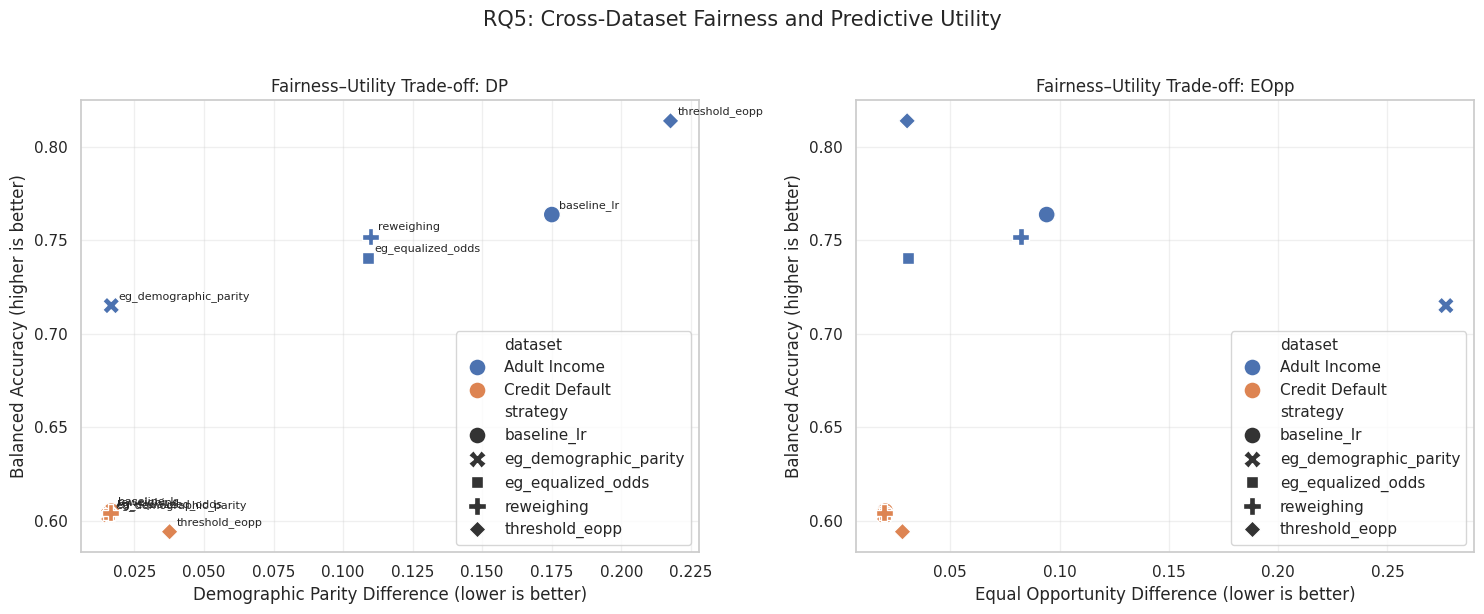

Saved: project22_outputs/figures/RQ5_Figure1_Cross_Dataset_Performance.png


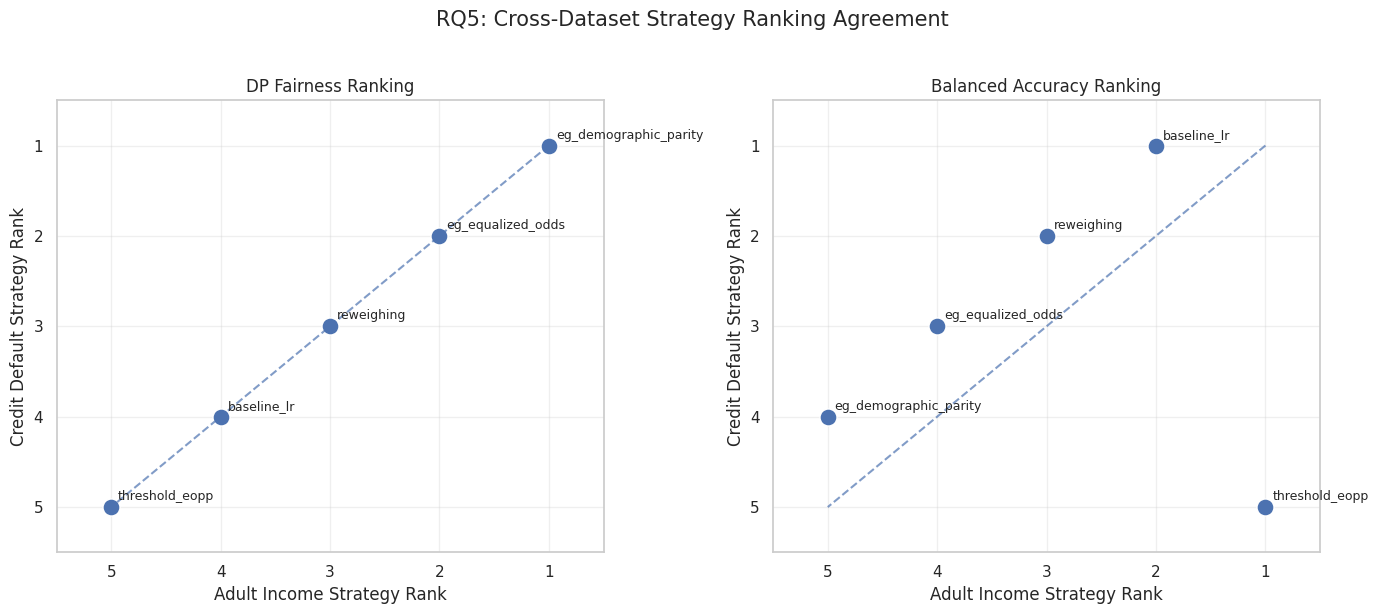

Saved: project22_outputs/figures/RQ5_Figure2_Strategy_Ranking_Agreement.png

SPEARMAN RANKING AGREEMENT
dp_rank: rho=1.000, p-value=0.0000, strategies=5
utility_rank: rho=0.000, p-value=1.0000, strategies=5

RQ5 FIGURE INVENTORY
RQ5_Figure1_Cross_Dataset_Performance.png: SAVED
RQ5_Figure2_Strategy_Ranking_Agreement.png: SAVED


In [36]:

# ============================================================
# RQ5 — FIGURE 1 & FIGURE 2
# CROSS-DATASET PERFORMANCE AND STRATEGY RANKING
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

# Use the existing RQ5 tables
cross_data = rq5_summary.copy()
rank_data = ranking_data.copy()

# ============================================================
# FIGURE 1 — CROSS-DATASET FAIRNESS–UTILITY COMPARISON
# ============================================================

# Aggregate over noise conditions and modes for each strategy.
# This prevents repeated condition rows from being treated as
# separate strategy-level observations.

cross_plot = (
    cross_data
    .groupby(["dataset", "strategy"], as_index=False)
    .agg(
        balanced_accuracy=("mean_balanced_accuracy", "mean"),
        dp_diff=("mean_dp_diff", "mean"),
        eopp_diff=("mean_eopp_diff", "mean"),
        eo_diff=("mean_eo_diff", "mean")
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A — DP fairness vs balanced accuracy
sns.scatterplot(
    data=cross_plot,
    x="dp_diff",
    y="balanced_accuracy",
    hue="dataset",
    style="strategy",
    s=150,
    ax=axes[0]
)

for _, row in cross_plot.iterrows():
    axes[0].annotate(
        row["strategy"],
        (row["dp_diff"], row["balanced_accuracy"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[0].set_title("Fairness–Utility Trade-off: DP")
axes[0].set_xlabel("Demographic Parity Difference (lower is better)")
axes[0].set_ylabel("Balanced Accuracy (higher is better)")
axes[0].grid(True, alpha=0.3)

# Panel B — EOpp fairness vs balanced accuracy
sns.scatterplot(
    data=cross_plot,
    x="eopp_diff",
    y="balanced_accuracy",
    hue="dataset",
    style="strategy",
    s=150,
    ax=axes[1]
)

axes[1].set_title("Fairness–Utility Trade-off: EOpp")
axes[1].set_xlabel("Equal Opportunity Difference (lower is better)")
axes[1].set_ylabel("Balanced Accuracy (higher is better)")
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    "RQ5: Cross-Dataset Fairness and Predictive Utility",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

path1 = FIG_DIR / "RQ5_Figure1_Cross_Dataset_Performance.png"
fig.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", path1)


# ============================================================
# FIGURE 2 — STRATEGY RANKING AGREEMENT
# ============================================================

required_rank = [
    "dataset", "strategy", "dp_rank", "utility_rank"
]

missing = [c for c in required_rank if c not in rank_data.columns]

if missing:
    raise ValueError(f"Missing ranking columns: {missing}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ranking_metrics = [
    ("dp_rank", "DP Fairness Ranking"),
    ("utility_rank", "Balanced Accuracy Ranking")
]

for ax, (metric, title) in zip(axes, ranking_metrics):

    sns.scatterplot(
        data=rank_data,
        x=metric,
        y=metric,
        hue="dataset",
        style="dataset",
        s=150,
        ax=ax
    )

    # Plot Adult vs Credit strategy ranks
    adult = (
        rank_data[rank_data["dataset"] == "Adult Income"]
        [["strategy", metric]]
        .rename(columns={metric: "adult_rank"})
    )

    credit = (
        rank_data[rank_data["dataset"] == "Credit Default"]
        [["strategy", metric]]
        .rename(columns={metric: "credit_rank"})
    )

    comparison = adult.merge(credit, on="strategy")

    ax.clear()

    sns.scatterplot(
        data=comparison,
        x="adult_rank",
        y="credit_rank",
        s=150,
        ax=ax
    )

    for _, row in comparison.iterrows():
        ax.annotate(
            row["strategy"],
            (row["adult_rank"], row["credit_rank"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

    # Perfect ranking agreement reference line
    ax.plot([1, 5], [1, 5], linestyle="--", alpha=0.7)

    ax.set_xlim(0.5, 5.5)
    ax.set_ylim(0.5, 5.5)
    ax.set_xticks(range(1, 6))
    ax.set_yticks(range(1, 6))
    ax.invert_xaxis()
    ax.invert_yaxis()

    ax.set_title(title)
    ax.set_xlabel("Adult Income Strategy Rank")
    ax.set_ylabel("Credit Default Strategy Rank")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "RQ5: Cross-Dataset Strategy Ranking Agreement",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

path2 = FIG_DIR / "RQ5_Figure2_Strategy_Ranking_Agreement.png"
fig.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", path2)


# ============================================================
# SPEARMAN RANKING AGREEMENT — DISPLAY
# ============================================================

from scipy.stats import spearmanr

print("\nSPEARMAN RANKING AGREEMENT")

for metric in ["dp_rank", "utility_rank"]:

    adult = (
        rank_data[rank_data["dataset"] == "Adult Income"]
        [["strategy", metric]]
        .rename(columns={metric: "adult"})
    )

    credit = (
        rank_data[rank_data["dataset"] == "Credit Default"]
        [["strategy", metric]]
        .rename(columns={metric: "credit"})
    )

    comparison = adult.merge(credit, on="strategy")

    rho, p_value = spearmanr(
        comparison["adult"],
        comparison["credit"]
    )

    print(
        f"{metric}: rho={rho:.3f}, "
        f"p-value={p_value:.4f}, "
        f"strategies={len(comparison)}"
    )


# ============================================================
# FINAL FIGURE INVENTORY
# ============================================================

print("\nRQ5 FIGURE INVENTORY")

for filename in [
    "RQ5_Figure1_Cross_Dataset_Performance.png",
    "RQ5_Figure2_Strategy_Ranking_Agreement.png"
]:
    path = FIG_DIR / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'NOT GENERATED'}")


## 16. Statistical analysis and robustness reporting

This section creates seed-level summaries and paired bootstrap intervals for selector contrasts. The bootstrap resamples independent seeds/paired conditions, not individual rows, and should be interpreted cautiously when the number of seeds is small. Final publication-level claims require the 20-seed final run and appropriate multiplicity control.

In [37]:
# ============================================================
# FAIRNESS ROBUSTNESS RATIO
# ============================================================

def paired_bootstrap_ci(values, reps=BOOTSTRAP_REPS, seed=321):
    x = np.asarray(pd.Series(values).dropna(), dtype=float)

    if len(x) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)

    b = np.array([
        np.mean(rng.choice(x, len(x), replace=True))
        for _ in range(reps)
    ])

    return (
        float(np.mean(x)),
        float(np.quantile(b, 0.025)),
        float(np.quantile(b, 0.975))
    )


# Zero-noise DP / noisy DP
# Also report absolute DP change.

robustness_rows = []

if not results.empty:

    group_columns = [
        "dataset",
        "group_design",
        "noise_mode",
        "strategy"
    ]

    for keys, g in results.groupby(group_columns):

        zero = g[
            g["train_noise_rate"] == 0
        ]["test_dp_diff"].mean()

        for rate, h in g.groupby("train_noise_rate"):

            noisy = h["test_dp_diff"].mean()

            ratio = (
                zero / noisy
                if pd.notna(noisy) and noisy > 1e-12
                else np.nan
            )

            robustness_rows.append({
                **dict(zip(group_columns, keys)),
                "noise_rate": rate,
                "zero_noise_dp": zero,
                "noisy_dp": noisy,
                "absolute_dp_change": noisy - zero,
                "robustness_ratio_zero_over_noisy": ratio
            })


robustness = pd.DataFrame(robustness_rows)

print("FAIRNESS ROBUSTNESS ANALYSIS")
print("=" * 60)

if not robustness.empty:
    display(robustness.head(20))
else:
    print("No robustness results available.")

FAIRNESS ROBUSTNESS ANALYSIS


,dataset,group_design,noise_mode,strategy,noise_rate,zero_noise_dp,noisy_dp,absolute_dp_change,robustness_ratio_zero_over_noisy
0,Adult Income,70_30,minority_to_majority,baseline_lr,0.3,NaN,0.172494,NaN,NaN
1,Adult Income,70_30,minority_to_majority,eg_demographic_parity,0.3,NaN,0.019152,NaN,NaN
2,Adult Income,70_30,minority_to_majority,eg_equalized_odds,0.3,NaN,0.093307,NaN,NaN
3,Adult Income,70_30,minority_to_majority,reweighing,0.3,NaN,0.115579,NaN,NaN
4,Adult Income,70_30,minority_to_majority,threshold_eopp,0.3,NaN,0.213647,NaN,NaN
5,Adult Income,70_30,symmetric,baseline_lr,0.0,0.172494,0.172494,0.000000e+00,1.000000
6,Adult Income,70_30,symmetric,baseline_lr,0.1,0.172494,0.172494,2.775558e-17,1.000000
7,Adult Income,70_30,symmetric,eg_demographic_parity,0.0,0.018365,0.018365,0.000000e+00,1.000000
8,Adult Income,70_30,symmetric,eg_demographic_parity,0.1,0.018365,0.024494,6.129030e-03,0.749771
9,Adult Income,70_30,symmetric,eg_equalized_odds,0.0,0.091230,0.091230,0.000000e+00,1.000000


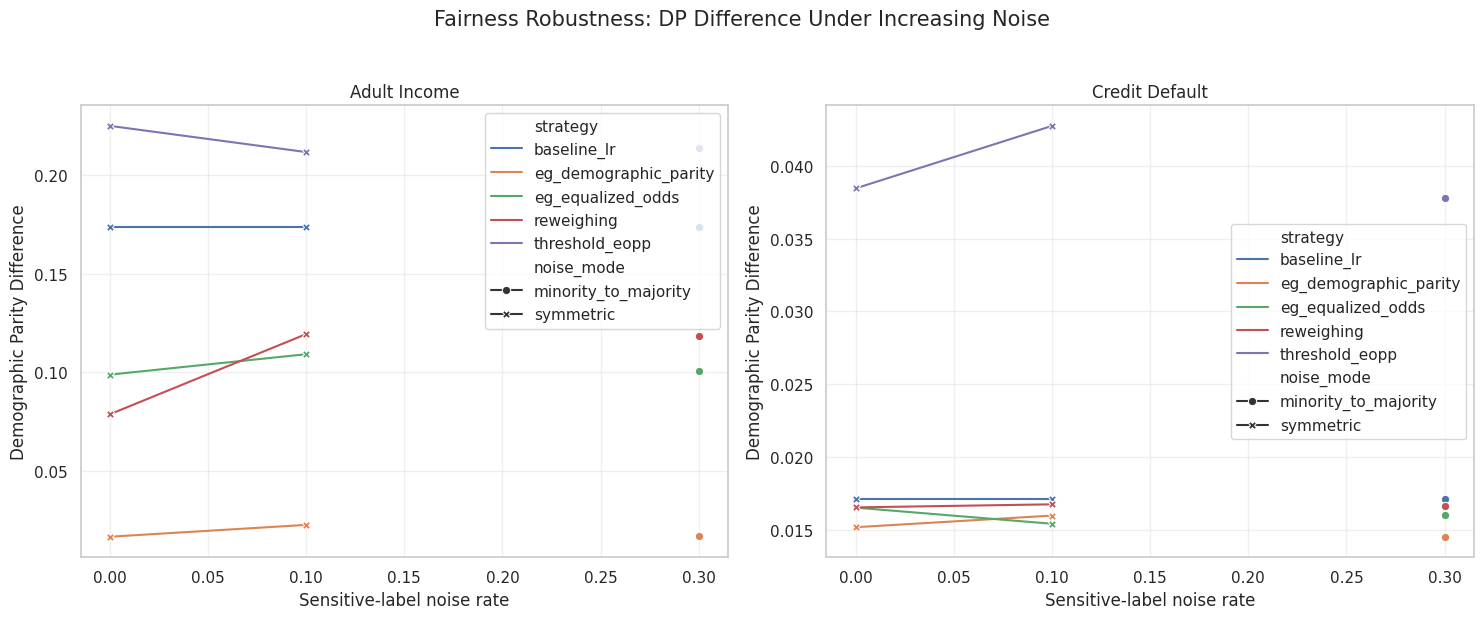

Saved: project22_outputs/figures/Robustness_Figure1_DP_vs_Noise.png


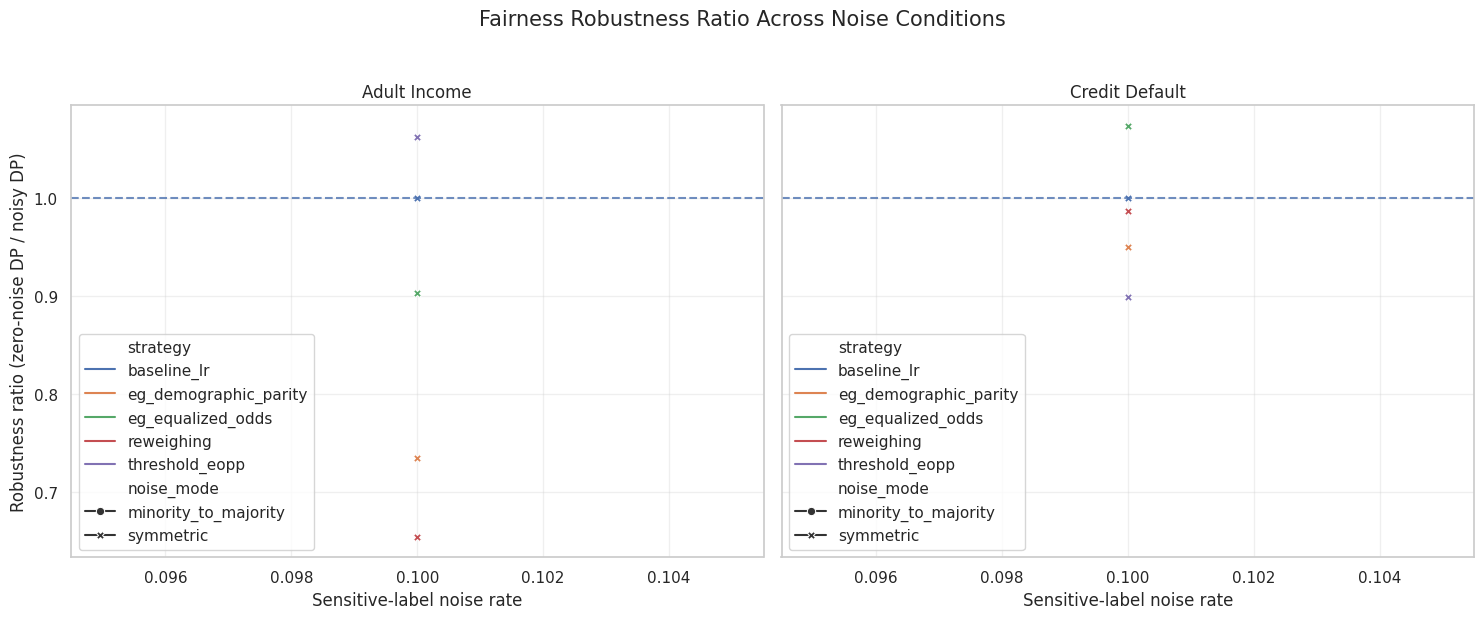

Saved: project22_outputs/figures/Robustness_Figure2_Robustness_Ratio.png

ROBUSTNESS FIGURE INVENTORY
Robustness_Figure1_DP_vs_Noise.png: SAVED
Robustness_Figure2_Robustness_Ratio.png: SAVED


In [38]:

# ============================================================
# FAIRNESS ROBUSTNESS ANALYSIS — FIGURE 1 & FIGURE 2
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

# Use the existing robustness table
robust_data = robustness.copy()

required_columns = [
    "dataset",
    "group_design",
    "noise_mode",
    "strategy",
    "noise_rate",
    "zero_noise_dp",
    "noisy_dp",
    "absolute_dp_change",
    "robustness_ratio_zero_over_noisy"
]

missing = [c for c in required_columns if c not in robust_data.columns]

if missing:
    raise ValueError(f"Missing robustness columns: {missing}")


# ============================================================
# FIGURE 1 — DP FAIRNESS GAP VS NOISE RATE
# ============================================================

plot_data = (
    robust_data
    .groupby(
        ["dataset", "noise_mode", "strategy", "noise_rate"],
        as_index=False
    )
    .agg(
        mean_dp=("noisy_dp", "mean")
    )
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    sharey=False
)

for ax, dataset in zip(
    axes,
    plot_data["dataset"].unique()
):

    subset = plot_data[plot_data["dataset"] == dataset]

    sns.lineplot(
        data=subset,
        x="noise_rate",
        y="mean_dp",
        hue="strategy",
        style="noise_mode",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("Sensitive-label noise rate")
    ax.set_ylabel("Demographic Parity Difference")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Fairness Robustness: DP Difference Under Increasing Noise",
    fontsize=15,
    y=1.03
)

plt.tight_layout()

path1 = FIG_DIR / "Robustness_Figure1_DP_vs_Noise.png"
fig.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", path1)


# ============================================================
# FIGURE 2 — ROBUSTNESS RATIO VS NOISE RATE
# ============================================================

ratio_data = robust_data[
    robust_data["noise_rate"] > 0
].copy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    sharey=True
)

for ax, dataset in zip(
    axes,
    ratio_data["dataset"].unique()
):

    subset = ratio_data[ratio_data["dataset"] == dataset]

    sns.lineplot(
        data=subset,
        x="noise_rate",
        y="robustness_ratio_zero_over_noisy",
        hue="strategy",
        style="noise_mode",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=ax
    )

    ax.axhline(
        y=1.0,
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label="Zero-noise reference"
    )

    ax.set_title(dataset)
    ax.set_xlabel("Sensitive-label noise rate")
    ax.set_ylabel("Robustness ratio (zero-noise DP / noisy DP)")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Fairness Robustness Ratio Across Noise Conditions",
    fontsize=15,
    y=1.03
)

plt.tight_layout()

path2 = FIG_DIR / "Robustness_Figure2_Robustness_Ratio.png"
fig.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", path2)


# ============================================================
# FIGURE INVENTORY
# ============================================================

print("\nROBUSTNESS FIGURE INVENTORY")

for filename in [
    "Robustness_Figure1_DP_vs_Noise.png",
    "Robustness_Figure2_Robustness_Ratio.png"
]:
    path = FIG_DIR / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'NOT GENERATED'}")


## 17. Export all tables, figures, configuration, failures and ZIP

The output folder contains raw run-level data, RQ summaries, subgroup metrics, target-imbalance sensitivity, cross-dataset comparisons, failures, and a configuration/limitations record. The ZIP is created only after all preceding analysis cells have run.

In [39]:

# ============================================================
# EXPORT ALL PROJECT 22 RESULTS
# ============================================================

# Ensure RQ5 export variables exist
# These are created by the corrected RQ5 analysis cell.

if "rq5_summary" in globals():
    cross = rq5_summary.copy()
else:
    cross = pd.DataFrame()

if "ranking_data" in globals():
    cross_rank = ranking_data.copy()
else:
    cross_rank = pd.DataFrame()


# Prepare all result tables
frames = {
    "table_dataset_audit.csv": audit_df,
    "table_all_model_runs.csv": results,
    "table_model_fit_failures.csv": pd.DataFrame(failure_rows),
    "table_model_selection_runs.csv": selections,
    "table_rq1_summary.csv": rq1_summary,
    "table_rq2_false_reassurance.csv": rq2_summary,
    "table_rq2_selector_disagreement_regret.csv": wide,
    "table_rq3_summary.csv": rq3_summary,
    "table_rq3_paired_bootstrap.csv": rq3_paired,
    "table_rq4_target_imbalance.csv": target_imbalance,
    "table_rq5_cross_dataset_effects.csv": cross,
    "table_rq5_strategy_rank_agreement.csv": cross_rank,
    "table_robustness_ratios.csv": robustness
}


# Export CSV files
for filename, df in frames.items():

    if isinstance(df, pd.DataFrame):
        df.to_csv(TABLE_DIR / filename, index=False)


# Save experiment configuration and limitations
config = {
    "project": "Project 22 — Fairness under Noisy Sensitive Labels",
    "run_mode": RUN_MODE,
    "seeds": SEEDS,
    "noise_rates": NOISE_RATES,
    "noise_modes": NOISE_MODES,
    "group_designs": GROUP_DESIGNS,
    "strategies": STRATEGIES,
    "fairness_thresholds": FAIRNESS_THRESHOLDS,
    "utility_floors": UTILITY_FLOORS,
    "max_rows": MAX_ROWS,
    "fairlearn_available": FAIRLEARN_AVAILABLE,
    "n_model_rows": len(results),
    "n_selector_rows": len(selections),
    "n_failures": len(failure_rows),
    "limitations": [
        "Pilot results are exploratory.",
        "Clean source labels are a reference, not objective ground truth.",
        "Target-prevalence extension resamples training data only.",
        "Threshold post-processing uses validation group labels.",
        "Noise-aware imputation relies on assumed corruption rates and requires sensitivity analysis.",
        "Cross-dataset comparison is replication, not domain adaptation.",
        "Check failures and all configuration values before interpreting results."
    ]
}

(OUTPUT_DIR / "run_configuration_and_limitations.json").write_text(
    json.dumps(config, indent=2)
)


# Create ZIP archive
zip_path = Path("Project22_results_" + RUN_MODE + ".zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for p in OUTPUT_DIR.rglob("*"):

        if p.is_file():
            z.write(
                p,
                arcname=str(p.relative_to(OUTPUT_DIR))
            )


# Final export report
print("=" * 60)
print("PROJECT 22 — EXPORT COMPLETED")
print("=" * 60)

print("Created:", zip_path.resolve())
print("Size MB:", round(zip_path.stat().st_size / 1e6, 2))

print("Tables:", sum(1 for p in TABLE_DIR.glob("*.csv")))
print("Figures:", sum(1 for p in FIG_DIR.glob("*")))

print("\nExported files:")
for filename in frames:
    print(" -", filename)


PROJECT 22 — EXPORT COMPLETED
Created: /kaggle/working/Project22_results_pilot.zip
Size MB: 4.11
Tables: 13
Figures: 14

Exported files:
 - table_dataset_audit.csv
 - table_all_model_runs.csv
 - table_model_fit_failures.csv
 - table_model_selection_runs.csv
 - table_rq1_summary.csv
 - table_rq2_false_reassurance.csv
 - table_rq2_selector_disagreement_regret.csv
 - table_rq3_summary.csv
 - table_rq3_paired_bootstrap.csv
 - table_rq4_target_imbalance.csv
 - table_rq5_cross_dataset_effects.csv
 - table_rq5_strategy_rank_agreement.csv
 - table_robustness_ratios.csv


## 18. Final completion checklist

Do not claim that every RQ is answered unless the checks below pass and the outputs are interpreted. A zero failure count is not mandatory if a method genuinely cannot fit, but every failure must be explained and the planned strategy comparison must be reported as incomplete if a core strategy is unavailable.

In [40]:
checks={
 "both_datasets_loaded":len(DATASETS)==2,
 "model_results_exist":not results.empty,
 "all_five_strategy_names_in_configuration":set(STRATEGIES)=={"baseline_lr","reweighing","eg_demographic_parity","eg_equalized_odds","threshold_eopp"},
 "fairlearn_dp_has_successful_runs":not results.empty and (results.strategy=="eg_demographic_parity").any(),
 "fairlearn_eo_has_successful_runs":not results.empty and (results.strategy=="eg_equalized_odds").any(),
 "rq2_outputs_exist":not rq2_summary.empty,
 "rq3_outputs_exist":not rq3_summary.empty,
 "rq4_target_imbalance_ran":not target_imbalance.empty,
 "rq5_cross_dataset_outputs_exist":not cross.empty,
 "at_least_20_seeds":len(SEEDS)>=20,
 "results_zip_exists":Path(zip_path).exists()
}
display(pd.DataFrame([{"check":k,"passed":v} for k,v in checks.items()]))
print("\nInterpretation rule:")
print("- If Fairlearn checks fail, RQ1's full strategy comparison remains incomplete.")
print("- If fewer than 20 seeds, report as pilot, not final.")
print("- If RQ3 safeguard does not outperform naive selection, report that honestly.")
print("- RQ4 requires both group-prevalence and target-prevalence outputs.")
print("- Do not use dummy values or infer unsupported positive conclusions.")

,check,passed
0,both_datasets_loaded,True
1,model_results_exist,True
2,all_five_strategy_names_in_configuration,True
3,fairlearn_dp_has_successful_runs,True
4,fairlearn_eo_has_successful_runs,True
5,rq2_outputs_exist,True
6,rq3_outputs_exist,True
7,rq4_target_imbalance_ran,True
8,rq5_cross_dataset_outputs_exist,True
9,at_least_20_seeds,False



Interpretation rule:
- If Fairlearn checks fail, RQ1's full strategy comparison remains incomplete.
- If fewer than 20 seeds, report as pilot, not final.
- If RQ3 safeguard does not outperform naive selection, report that honestly.
- RQ4 requires both group-prevalence and target-prevalence outputs.
- Do not use dummy values or infer unsupported positive conclusions.
